
**Hypothesis 2:** *Accidents do not happen randomly; they cluster in specific spots and time periods.*

This notebook:
1. Connects to the PostgreSQL Data Warehouse (`version3-Dwh-mining`, port)
2. Queries `mart.spatial_clustering JOIN mart.collision_context` for all geocoded collisions
3. Engineers features needed for **location × time classification**
4. Saves the cleaned dataset to `Support/Generated/H2_Results/h2_classification_dataset.csv`

**Target variable:** `severe_fatal` (1 = severe injury or fatal, 0 = otherwise)

**Features used for classification:**
- Spatial: `latitude`, `longitude`, `county_name`
- Temporal: `hour`, `day_of_week`, `month`, `year`, `is_weekend`, `is_night`
- Outcome context: `killed`, `injured`

In [2]:
# ── 0. Imports & configuration ──────────────────────────────────────────────
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv

# Project paths (notebook lives in Python/, DWH root is one level up)
ROOT = Path("__file__").resolve().parent.parent   # DWH-Mining/
ROOT = Path.cwd().parent                          # works when cwd = Python/
if not (ROOT / ".env").exists():
    ROOT = Path.cwd()                             # fallback: running from root

OUT  = ROOT / "Support" / "Generated" / "H2_Results"
OUT.mkdir(parents=True, exist_ok=True)

# Load credentials from .env
load_dotenv(ROOT / ".env")
load_dotenv()

print(f"Project root : {ROOT}")
print(f"Output folder: {OUT}")

Project root : d:\win min oo\mahidol\Data Mining and data warehose\project\version3\DWH-Mining
Output folder: d:\win min oo\mahidol\Data Mining and data warehose\project\version3\DWH-Mining\Support\Generated\H2_Results


In [3]:
# ── 1. Database connection settings ─────────────────────────────────────────
import getpass

DB_HOST = os.getenv("PGHOST",     "localhost")
DB_PORT = int(os.getenv("PGPORT", "2001"))
DB_NAME = os.getenv("PGDATABASE", "version3-Dwh-mining")
DB_USER = os.getenv("PGUSER",     "postgres")
DB_PASS = os.getenv("PGPASSWORD") or getpass.getpass("PostgreSQL password: ")

print(f"Connecting to {DB_HOST}:{DB_PORT}/{DB_NAME} as {DB_USER}")

Connecting to localhost:2001/version3-Dwh-mining as postgres


In [4]:
# ── 2. SQL query – fetch all geocoded collisions with spatial + temporal + severity info ──
QUERY = """
SELECT
    s.case_id,
    s.full_date,
    s.hour,
    s.latitude,
    s.longitude,
    c.severity,
    c.county_name,
    c.killed,
    c.injured,
    c.severe_or_fatal,          -- pre-computed boolean in mart
    c.is_weekend
FROM  mart.spatial_clustering s
JOIN  mart.collision_context  c USING (case_id)
"""

print("Running query…")
t0 = time.time()

try:
    import psycopg as pg          # psycopg 3
    conn_cls = pg
except ImportError:
    import psycopg2 as pg         # psycopg 2
    conn_cls = pg

with pg.connect(
    host=DB_HOST, port=DB_PORT, dbname=DB_NAME,
    user=DB_USER, password=DB_PASS
) as conn:
    with conn.cursor() as cur:
        cur.execute(QUERY)
        cols = [d[0] for d in cur.description]
        rows = cur.fetchall()

raw = pd.DataFrame(rows, columns=cols)
print(f"Fetched {len(raw):,} rows in {time.time() - t0:.1f}s")
raw.head(3)

Running query…
Fetched 2,693,995 rows in 34.8s


,case_id,full_date,hour,latitude,longitude,severity,county_name,killed,injured,severe_or_fatal,is_weekend
0,3995235,2009-01-09,0.0,34.20028,-118.33869,property damage only,Los Angeles County,0,0,0,False
1,4054318,2009-01-23,17.0,34.04194,-118.06227,other injury,Los Angeles County,0,1,0,False
2,4054382,2009-01-23,11.0,34.05685,-118.24268,pain,Los Angeles County,0,1,0,False


In [5]:
# ── 3. Basic type casting ────────────────────────────────────────────────────
df = raw.copy()

df["full_date"]   = pd.to_datetime(df["full_date"],  errors="coerce")
df["latitude"]    = pd.to_numeric(df["latitude"],    errors="coerce")
df["longitude"]   = pd.to_numeric(df["longitude"],   errors="coerce")
df["hour"]        = pd.to_numeric(df["hour"],        errors="coerce")
df["killed"]      = pd.to_numeric(df["killed"],      errors="coerce").fillna(0).astype(int)
df["injured"]     = pd.to_numeric(df["injured"],     errors="coerce").fillna(0).astype(int)
df["severity"]    = df["severity"].astype(str).str.lower().str.strip()
df["county_name"] = df["county_name"].astype(str).str.strip().str.upper()

print(df.dtypes)
print(f"\nNull counts:\n{df.isnull().sum()}")

case_id                      str
full_date          datetime64[s]
hour                     float64
latitude                 float64
longitude                float64
severity                     str
county_name                  str
killed                     int64
injured                    int64
severe_or_fatal            int64
is_weekend                  bool
dtype: object

Null counts:
case_id                0
full_date              0
hour               22898
latitude               0
longitude              0
severity               0
county_name            0
killed                 0
injured                0
severe_or_fatal        0
is_weekend             0
dtype: int64


In [6]:
# ── 4. Feature engineering ───────────────────────────────────────────────────
SEVERE_LABELS = {"severe injury", "fatal"}
NIGHT_HOURS   = set(range(20, 24)) | set(range(0, 6))   # 20:00 – 05:59

df["year"]         = df["full_date"].dt.year
df["month"]        = df["full_date"].dt.month
df["day_of_week"]  = df["full_date"].dt.day_of_week   # 0=Mon … 6=Sun
df["day_name"]     = df["full_date"].dt.day_name()

# is_weekend: use mart column if available, else derive
if "is_weekend" in df.columns and df["is_weekend"].notna().any():
    df["is_weekend"] = df["is_weekend"].astype(bool)
else:
    df["is_weekend"] = df["day_of_week"] >= 5

# is_night flag
df["is_night"] = df["hour"].isin(NIGHT_HOURS)

# Binary classification target
if "severe_or_fatal" in df.columns and df["severe_or_fatal"].notna().any():
    df["severe_fatal"] = df["severe_or_fatal"].astype(int)
else:
    df["severe_fatal"] = df["severity"].isin(SEVERE_LABELS).astype(int)

# Severity label for reference
df["severity_label"] = df["severity"]

print("severe_fatal value counts:")
print(df["severe_fatal"].value_counts())
print(f"\nClass balance: {df['severe_fatal'].mean()*100:.2f}% severe/fatal")

severe_fatal value counts:
severe_fatal
0    2595301
1      98694
Name: count, dtype: int64

Class balance: 3.66% severe/fatal


In [7]:
# ── 5. Drop rows with missing spatial / temporal / target data ───────────────
before = len(df)
df = df.dropna(subset=["latitude", "longitude", "full_date", "severe_fatal"])

# Keep only California bounding box
CA_LAT = (32.5, 42.0)
CA_LON = (-124.5, -114.1)
df = df[
    df["latitude"].between(*CA_LAT) &
    df["longitude"].between(*CA_LON)
]

print(f"Rows before cleaning: {before:,}")
print(f"Rows after  cleaning: {len(df):,}  ({before - len(df):,} removed)")

Rows before cleaning: 2,693,995
Rows after  cleaning: 2,693,980  (15 removed)


In [8]:
# ── 6. Final column selection & ordering ────────────────────────────────────
COLS = [
    # Identifier
    "case_id",
    # Temporal features
    "full_date", "year", "month", "day_of_week", "day_name", "hour",
    "is_weekend", "is_night",
    # Spatial features
    "latitude", "longitude", "county_name",
    # Outcome / auxiliary
    "killed", "injured",
    # Target
    "severity_label", "severe_fatal"
]
df = df[COLS].reset_index(drop=True)

print(f"Final dataset shape: {df.shape}")
df.head()

Final dataset shape: (2693980, 16)


,case_id,full_date,year,month,day_of_week,day_name,hour,is_weekend,is_night,latitude,longitude,county_name,killed,injured,severity_label,severe_fatal
0,3995235,2009-01-09,2009,1,4,Friday,0.0,False,True,34.20028,-118.33869,LOS ANGELES COUNTY,0,0,property damage only,0
1,4054318,2009-01-23,2009,1,4,Friday,17.0,False,False,34.04194,-118.06227,LOS ANGELES COUNTY,0,1,other injury,0
2,4054382,2009-01-23,2009,1,4,Friday,11.0,False,False,34.05685,-118.24268,LOS ANGELES COUNTY,0,1,pain,0
3,4055495,2009-01-06,2009,1,1,Tuesday,16.0,False,False,37.28778,-120.46971,MERCED COUNTY,0,0,property damage only,0
4,4055588,2009-01-02,2009,1,4,Friday,14.0,False,False,34.91538,-116.78555,SAN BERNARDINO COUNTY,0,0,property damage only,0


In [9]:
# ── 7. Quick summary statistics ──────────────────────────────────────────────
print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)
print(f"Total records        : {len(df):,}")
print(f"Date range           : {df['full_date'].min().date()} → {df['full_date'].max().date()}")
print(f"Years covered        : {sorted(df['year'].unique())}")
print(f"Counties             : {df['county_name'].nunique()} unique")
print(f"Severe/fatal (1)     : {df['severe_fatal'].sum():,}  ({df['severe_fatal'].mean()*100:.2f}%)")
print(f"Non-severe   (0)     : {(1 - df['severe_fatal']).sum():,}")
print(f"Night collisions     : {df['is_night'].sum():,}  ({df['is_night'].mean()*100:.2f}%)")
print(f"Weekend collisions   : {df['is_weekend'].sum():,}  ({df['is_weekend'].mean()*100:.2f}%)")
print()
print("Top 10 counties by collisions:")
print(df["county_name"].value_counts().head(10).to_string())

DATASET SUMMARY
Total records        : 2,693,980
Date range           : 2006-05-03 → 2021-06-03
Years covered        : [np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021)]
Counties             : 58 unique
Severe/fatal (1)     : 98,693  (3.66%)
Non-severe   (0)     : 2,595,287
Night collisions     : 622,889  (23.12%)
Weekend collisions   : 683,284  (25.36%)

Top 10 counties by collisions:
county_name
LOS ANGELES COUNTY       697244
ORANGE COUNTY            193173
RIVERSIDE COUNTY         173581
SAN DIEGO COUNTY         163142
SAN BERNARDINO COUNTY    134727
ALAMEDA COUNTY           132203
SACRAMENTO COUNTY        120114
SANTA CLARA COUNTY       110481
KERN COUNTY               90473
SAN JOAQUIN COUNTY        82820


In [10]:
# ── 8. Save to CSV ────────────────────────────────────────────────────────────
out_path = OUT / "h2_fetched_dataset.csv"
df.to_csv(out_path, index=False)

size_mb = out_path.stat().st_size / 1_048_576
print(f"✅ Saved → {out_path}")
print(f"   Rows : {len(df):,}")
print(f"   Size : {size_mb:.1f} MB")
print(f"   Cols : {list(df.columns)}")

✅ Saved → d:\win min oo\mahidol\Data Mining and data warehose\project\version3\DWH-Mining\Support\Generated\H2_Results\h2_fetched_dataset.csv
   Rows : 2,693,980
   Size : 291.0 MB
   Cols : ['case_id', 'full_date', 'year', 'month', 'day_of_week', 'day_name', 'hour', 'is_weekend', 'is_night', 'latitude', 'longitude', 'county_name', 'killed', 'injured', 'severity_label', 'severe_fatal']


## Dataset columns reference

| Column | Type | Description |
|:---|:---|:---|
| `case_id` | str | Unique collision identifier |
| `full_date` | datetime | Date of collision |
| `year` | int | Year (2006–2021) |
| `month` | int | Month (1–12) |
| `day_of_week` | int | 0 = Monday … 6 = Sunday |
| `day_name` | str | e.g. 'Monday' |
| `hour` | float | Hour of day (0–23), NaN if unknown |
| `is_weekend` | bool | True if Saturday or Sunday |
| `is_night` | bool | True if hour ∈ {20–23, 0–5} |
| `latitude` | float | GPS latitude |
| `longitude` | float | GPS longitude |
| `county_name` | str | California county (upper case) |
| `killed` | int | Number of fatalities |
| `injured` | int | Number of injuries |
| `severity_label` | str | Raw severity string from SWITRS |
| **`severe_fatal`** | **int** | **Target: 1 = severe injury or fatal, 0 = otherwise** |

In [ ]:
from pathlib import Path

# Walk up from the notebook's folder until we find the project root (the folder containing "Support")
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_PATH = ROOT / "Support" / "Generated" / "H2_Results" / "h2_fetched_dataset.csv"

# Show only the relative path (hides your personal folders)
print("Reading:", DATA_PATH.relative_to(ROOT))

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Reading: Support\Generated\H2_Results\h2_fetched_dataset.csv
(2693980, 16)


,case_id,full_date,year,month,day_of_week,day_name,hour,is_weekend,is_night,latitude,longitude,county_name,killed,injured,severity_label,severe_fatal
0,3995235,2009-01-09,2009,1,4,Friday,0.0,False,True,34.20028,-118.33869,LOS ANGELES COUNTY,0,0,property damage only,0
1,4054318,2009-01-23,2009,1,4,Friday,17.0,False,False,34.04194,-118.06227,LOS ANGELES COUNTY,0,1,other injury,0
2,4054382,2009-01-23,2009,1,4,Friday,11.0,False,False,34.05685,-118.24268,LOS ANGELES COUNTY,0,1,pain,0
3,4055495,2009-01-06,2009,1,1,Tuesday,16.0,False,False,37.28778,-120.46971,MERCED COUNTY,0,0,property damage only,0
4,4055588,2009-01-02,2009,1,4,Friday,14.0,False,False,34.91538,-116.78555,SAN BERNARDINO COUNTY,0,0,property damage only,0


In [19]:
df.isna().sum()

case_id               0
full_date             0
year                  0
month                 0
day_of_week           0
day_name              0
hour              22897
is_weekend            0
is_night              0
latitude              0
longitude             0
county_name           0
killed                0
injured               0
severity_label        0
severe_fatal          0
dtype: int64

In [20]:
total_rows = len(df)
unique_cases = df["case_id"].nunique()
duplicate_rows = total_rows - unique_cases

print(f"Total rows:      {total_rows:,}")
print(f"Unique case_id:  {unique_cases:,}")
print(f"Duplicate rows:  {duplicate_rows:,}")

# Optional: inspect a duplicate case_id if any exist
if duplicate_rows > 0:
    dup_ids = df[df.duplicated("case_id", keep=False)]["case_id"].unique()
    display(df[df["case_id"] == dup_ids[0]])

Total rows:      2,693,980
Unique case_id:  2,693,980
Duplicate rows:  0


In [21]:
# 1. Check for invalid/out-of-bounds coordinates (California bounding box check)
valid_coords = (
    df["latitude"].between(32.0, 42.5) &
    df["longitude"].between(-125.0, -114.0)
)
print(f"Valid coordinates: {valid_coords.sum():,} / {len(df):,}")

df_geo = df[valid_coords].copy()

# 2. Count accidents by county/district & rank top areas
county_summary = (
    df_geo.groupby("county_name", as_index=False)
    .agg(
        total_collisions=("case_id", "count"),
        severe_fatal_count=("severe_fatal", "sum"),
        total_killed=("killed", "sum"),
        total_injured=("injured", "sum"),
    )
    .sort_values("total_collisions", ascending=False)
)
county_summary["pct_of_total"] = (county_summary["total_collisions"] / len(df_geo) * 100).round(2)
county_summary["severe_rate_pct"] = (county_summary["severe_fatal_count"] / county_summary["total_collisions"] * 100).round(2)

print("\nTop 15 Counties by Collision Count:")
display(county_summary.head(15))

Valid coordinates: 2,693,980 / 2,693,980

Top 15 Counties by Collision Count:


,county_name,total_collisions,severe_fatal_count,total_killed,total_injured,pct_of_total,severe_rate_pct
18,LOS ANGELES COUNTY,697244,15352,3487,315958,25.88,2.20
29,ORANGE COUNTY,193173,4499,1108,95658,7.17,2.33
32,RIVERSIDE COUNTY,173581,7007,2097,93885,6.44,4.04
36,SAN DIEGO COUNTY,163142,6713,1659,96262,6.06,4.11
35,SAN BERNARDINO COUNTY,134727,6266,1981,72757,5.00,4.65
0,ALAMEDA COUNTY,132203,3056,588,55540,4.91,2.31
33,SACRAMENTO COUNTY,120114,3796,991,58159,4.46,3.16
42,SANTA CLARA COUNTY,110481,2932,711,54137,4.10,2.65
14,KERN COUNTY,90473,4228,1520,48645,3.36,4.67
38,SAN JOAQUIN COUNTY,82820,3460,1033,44739,3.07,4.18


In [25]:
# Round coordinates to ~110m grid cells (0.001 degrees) to approximate intersections/road segments
df_geo["lat_bin"] = df_geo["latitude"].round(3)
df_geo["lon_bin"] = df_geo["longitude"].round(3)

micro_hotspots = (
    df_geo.groupby(["county_name", "lat_bin", "lon_bin"], as_index=False)
    .agg(
        collisions=("case_id", "count"),
        severe_fatal=("severe_fatal", "sum"),
        killed=("killed", "sum"),
    )
    .sort_values("collisions", ascending=False)
)

print("Top 15 Micro-Hotspot Locations (~110m cells):")
display(micro_hotspots.head(15))

Top 15 Micro-Hotspot Locations (~110m cells):


,county_name,lat_bin,lon_bin,collisions,severe_fatal,killed
389942,SACRAMENTO COUNTY,38.493,-121.543,773,6,0
189460,LOS ANGELES COUNTY,34.059,-118.253,484,3,1
189249,LOS ANGELES COUNTY,34.058,-118.254,475,3,1
379031,SACRAMENTO COUNTY,38.000,-121.000,386,6,1
392866,SACRAMENTO COUNTY,38.545,-121.474,360,4,0
311362,ORANGE COUNTY,33.747,-117.843,348,0,0
187438,LOS ANGELES COUNTY,34.050,-118.263,345,3,3
176273,LOS ANGELES COUNTY,34.010,-117.824,340,2,0
19123,ALAMEDA COUNTY,37.837,-122.296,329,3,1
188813,LOS ANGELES COUNTY,34.056,-118.256,327,8,1


In [26]:
import folium
from folium.plugins import HeatMap

center_lat = df_geo["latitude"].median()
center_lon = df_geo["longitude"].median()

m = folium.Map(location=[center_lat, center_lon], zoom_start=6, tiles="OpenStreetMap")

sample_df = df_geo.sample(n=min(100_000, len(df_geo)), random_state=42)
heat_data = sample_df[["latitude", "longitude"]].values.tolist()

# Smooth blue -> yellow -> orange -> deep red gradient (no green)
no_green_gradient = {
    0.0: "#3b4cc0",   # soft blue (lowest density)
    0.3: "#ffe680",   # light yellow (low-moderate)
    0.55: "#ff9900",  # vibrant orange (moderate-high)
    0.8: "#e62e00",   # bright red (high)
    1.0: "#800000",   # dark crimson red (highest density)
}

HeatMap(
    heat_data,
    radius=10,
    blur=15,
    max_zoom=13,
    gradient=no_green_gradient,
    name="Accident Density Heatmap",
).add_to(m)

hotspot_group = folium.FeatureGroup(name="Top 20 Hotspot Intersections/Blocks")
for _, row in micro_hotspots.head(20).iterrows():
    folium.CircleMarker(
        location=[row["lat_bin"], row["lon_bin"]],
        radius=7,
        color="black",
        fill=True,
        fill_color="darkred",
        fill_opacity=0.85,
        popup=(
            f"<b>{row['county_name']}</b><br>"
            f"Coords: ({row['lat_bin']}, {row['lon_bin']})<br>"
            f"Collisions: {row['collisions']:,}<br>"
            f"Severe/Fatal: {row['severe_fatal']:,}"
        ),
    ).add_to(hotspot_group)

hotspot_group.add_to(m)
folium.LayerControl().add_to(m)

m

=== Accidents by Day of Week ===


,day_name,collisions,severe_fatal,severe_rate_pct
1,Monday,374053,12192,3.26
5,Tuesday,390629,11540,2.95
6,Wednesday,393801,11806,3.00
4,Thursday,404022,12662,3.13
0,Friday,448191,15174,3.39
2,Saturday,369802,17972,4.86
3,Sunday,313482,17347,5.53



=== Accidents by Month ===


,month,month_name,collisions,severe_fatal,severe_rate_pct
0,1,Jan,219315,7257,3.31
1,2,Feb,212427,7074,3.33
2,3,Mar,234038,7892,3.37
3,4,Apr,219707,8188,3.73
4,5,May,226134,8593,3.80
5,6,Jun,206732,8213,3.97
6,7,Jul,211153,8645,4.09
7,8,Aug,223754,8946,4.00
8,9,Sep,224015,8737,3.90
9,10,Oct,247107,9144,3.70


C:\Users\USER\AppData\Local\Temp\ipykernel_9488\2178086059.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_counts, x="hour", y="collisions", ax=axes[0, 0], palette="YlOrRd")
C:\Users\USER\AppData\Local\Temp\ipykernel_9488\2178086059.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow_counts, x="day_name", y="collisions", ax=axes[0, 1], palette="YlOrRd")
C:\Users\USER\AppData\Local\Temp\ipykernel_9488\2178086059.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_counts, x="month_name", y="collisions",

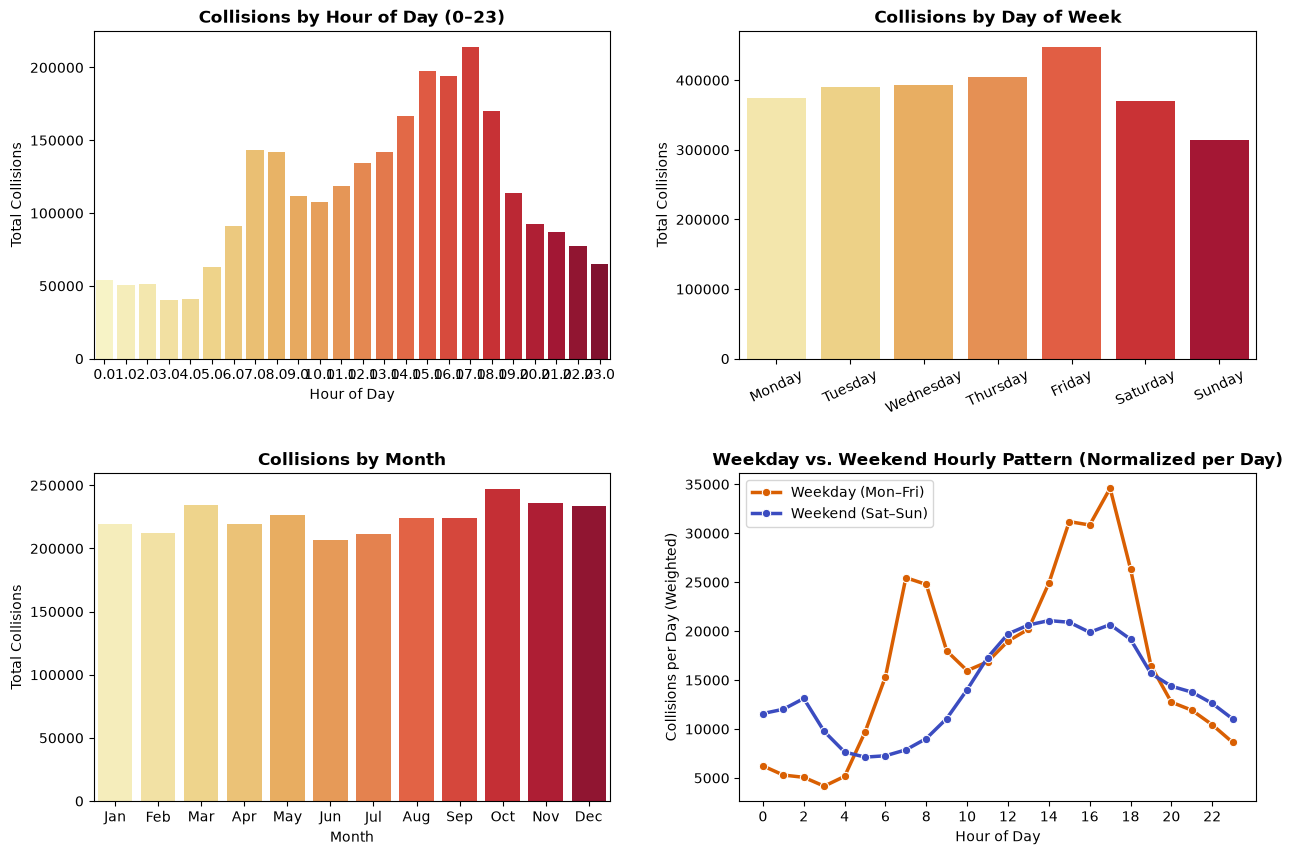

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure proper chronological ordering for days and months
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 1. Count accidents by hour (0-23)
hourly_counts = (
    df.groupby("hour", as_index=False)
    .agg(collisions=("case_id", "count"), severe_fatal=("severe_fatal", "sum"))
)
hourly_counts["severe_rate_pct"] = (hourly_counts["severe_fatal"] / hourly_counts["collisions"] * 100).round(2)

# 2. Count accidents by day of the week
dow_counts = (
    df.groupby("day_name", as_index=False)
    .agg(collisions=("case_id", "count"), severe_fatal=("severe_fatal", "sum"))
)
dow_counts["day_name"] = pd.Categorical(dow_counts["day_name"], categories=day_order, ordered=True)
dow_counts = dow_counts.sort_values("day_name")
dow_counts["severe_rate_pct"] = (dow_counts["severe_fatal"] / dow_counts["collisions"] * 100).round(2)

# 3. Count accidents by month (1-12)
monthly_counts = (
    df.groupby("month", as_index=False)
    .agg(collisions=("case_id", "count"), severe_fatal=("severe_fatal", "sum"))
)
monthly_counts["month_name"] = monthly_counts["month"].apply(lambda m: month_names[m - 1])
monthly_counts["severe_rate_pct"] = (monthly_counts["severe_fatal"] / monthly_counts["collisions"] * 100).round(2)

# 4. Compare Weekday vs. Weekend hourly patterns (normalized by number of days in group)
wk_hourly = (
    df.groupby(["is_weekend", "hour"], as_index=False)
    .agg(collisions=("case_id", "count"), severe_fatal=("severe_fatal", "sum"))
)
# Divide by 5 for weekdays (Mon-Fri) and 2 for weekends (Sat-Sun) to compare average daily rate
wk_hourly["avg_collisions_per_day"] = wk_hourly.apply(
    lambda r: r["collisions"] / (2 if r["is_weekend"] else 5), axis=1
)
wk_hourly["day_type"] = wk_hourly["is_weekend"].map({False: "Weekday (Mon–Fri)", True: "Weekend (Sat–Sun)"})

# Print summary tables
print("=== Accidents by Day of Week ===")
display(dow_counts)
print("\n=== Accidents by Month ===")
display(monthly_counts[["month", "month_name", "collisions", "severe_fatal", "severe_rate_pct"]])

# --- 2x2 Temporal Hotspot Dashboard ---
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Plot A: By Hour
sns.barplot(data=hourly_counts, x="hour", y="collisions", ax=axes[0, 0], palette="YlOrRd")
axes[0, 0].set_title("Collisions by Hour of Day (0–23)", fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Total Collisions")

# Plot B: By Day of Week
sns.barplot(data=dow_counts, x="day_name", y="collisions", ax=axes[0, 1], palette="YlOrRd")
axes[0, 1].set_title("Collisions by Day of Week", fontweight="bold")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Total Collisions")
axes[0, 1].tick_params(axis="x", rotation=25)

# Plot C: By Month
sns.barplot(data=monthly_counts, x="month_name", y="collisions", ax=axes[1, 0], palette="YlOrRd")
axes[1, 0].set_title("Collisions by Month", fontweight="bold")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Total Collisions")

# Plot D: Weekday vs. Weekend Hourly Pattern (Normalized per Day)
sns.lineplot(
    data=wk_hourly,
    x="hour",
    y="avg_collisions_per_day",
    hue="day_type",
    palette={"Weekday (Mon–Fri)": "#d95f02", "Weekend (Sat–Sun)": "#3b4cc0"},
    linewidth=2.5,
    marker="o",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Weekday vs. Weekend Hourly Pattern (Normalized per Day)", fontweight="bold")
axes[1, 1].set_xlabel("Hour of Day")
axes[1, 1].set_ylabel("Collisions per Day (Weighted)")
axes[1, 1].set_xticks(range(0, 24, 2))
axes[1, 1].legend(title="")

plt.show()

In [33]:
from pathlib import Path

# 0. Find project root (folder containing "Support") and set output folder
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

OUT_DIR = ROOT / "Support" / "Generated" / "H2_Results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Slim sample for fitting KDE quickly (only lat/lon cast to float32)
kde_sample_lite = (
    df_geo.sample(n=min(50_000, len(df_geo)), random_state=42)[["latitude", "longitude"]]
    .astype("float32")
    .reset_index(drop=True)
)

# 2. Pre-aggregated micro-hotspots (~110m bins) with compact numeric types
micro_hotspots_lite = micro_hotspots[
    ["county_name", "lat_bin", "lon_bin", "collisions", "severe_fatal"]
].copy()
micro_hotspots_lite["lat_bin"] = micro_hotspots_lite["lat_bin"].astype("float32")
micro_hotspots_lite["lon_bin"] = micro_hotspots_lite["lon_bin"].astype("float32")
micro_hotspots_lite["collisions"] = micro_hotspots_lite["collisions"].astype("int32")
micro_hotspots_lite["severe_fatal"] = micro_hotspots_lite["severe_fatal"].astype("int32")

# 3. Save lightweight Parquet files to Support/Generated/H2_Results/
kde_path = OUT_DIR / "kde_sample_lite.parquet"
hotspots_path = OUT_DIR / "micro_hotspots_lite.parquet"

kde_sample_lite.to_parquet(kde_path, index=False)
micro_hotspots_lite.to_parquet(hotspots_path, index=False)

print("Saved kde_sample_lite:", kde_sample_lite.shape, "->", kde_path.relative_to(ROOT))
print("Saved micro_hotspots_lite:", micro_hotspots_lite.shape, "->", hotspots_path.relative_to(ROOT))

Saved kde_sample_lite: (50000, 2) -> Support\Generated\H2_Results\kde_sample_lite.parquet
Saved micro_hotspots_lite: (662400, 5) -> Support\Generated\H2_Results\micro_hotspots_lite.parquet


=== Top 15 Geographical Hotspots Ranked by KDE Density ===


,county_name,lat_bin,lon_bin,collisions,severe_fatal,kde_density
258348,LOS ANGELES COUNTY,34.002998,-118.176003,2,0,1.042633
258741,LOS ANGELES COUNTY,34.001999,-118.175003,2,0,1.042629
566169,LOS ANGELES COUNTY,34.004002,-118.177002,1,0,1.042619
258347,LOS ANGELES COUNTY,34.002998,-118.175003,2,0,1.042617
5195,LOS ANGELES COUNTY,34.001999,-118.174004,55,0,1.042611
14765,LOS ANGELES COUNTY,34.000999,-118.174004,30,0,1.042609
565555,LOS ANGELES COUNTY,34.001999,-118.176003,1,0,1.042582
1944,LOS ANGELES COUNTY,34.000999,-118.175003,81,0,1.042564
566622,LOS ANGELES COUNTY,34.006001,-118.179001,1,0,1.042539
7145,LOS ANGELES COUNTY,34.002998,-118.174004,47,0,1.042535


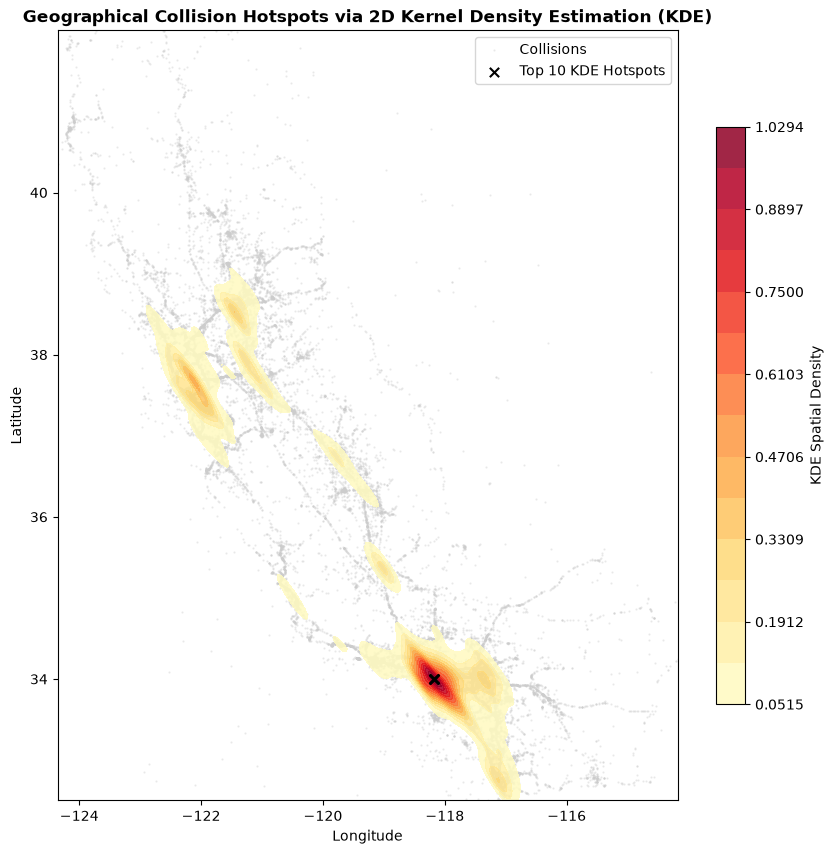

In [35]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# 0. Locate project root and the folder where the parquet files were saved
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

OUT_DIR = ROOT / "Support" / "Generated" / "H2_Results"

# 1. Load lightweight datasets from Support/Generated/H2_Results/
kde_sample = pd.read_parquet(OUT_DIR / "kde_sample_lite.parquet")
micro_hotspots_kde = pd.read_parquet(OUT_DIR / "micro_hotspots_lite.parquet")

coords = np.vstack([kde_sample["longitude"], kde_sample["latitude"]])

# Fit Gaussian KDE (adjust bw_method smaller like 0.05 for sharper city-level peaks)
kde = gaussian_kde(coords, bw_method=0.08)

# 2. Evaluate KDE density across a 2D spatial grid for contour/surface mapping
lon_min, lon_max = kde_sample["longitude"].min(), kde_sample["longitude"].max()
lat_min, lat_max = kde_sample["latitude"].min(), kde_sample["latitude"].max()

lon_grid, lat_grid = np.mgrid[lon_min:lon_max:250j, lat_min:lat_max:250j]
grid_positions = np.vstack([lon_grid.ravel(), lat_grid.ravel()])
kde_surface = np.reshape(kde(grid_positions).T, lon_grid.shape)

# 3. Score micro-hotspots with exact KDE density values to rank top hotspots
hotspot_coords = np.vstack([micro_hotspots_kde["lon_bin"], micro_hotspots_kde["lat_bin"]])
micro_hotspots_kde["kde_density"] = kde(hotspot_coords)

top_kde_hotspots = micro_hotspots_kde.sort_values("kde_density", ascending=False)
print("=== Top 15 Geographical Hotspots Ranked by KDE Density ===")
display(
    top_kde_hotspots[["county_name", "lat_bin", "lon_bin", "collisions", "severe_fatal", "kde_density"]].head(15)
)

# 4. Plot the 2D KDE Spatial Hotspot Contour Map (YlOrRd - no green)
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(
    kde_sample["longitude"],
    kde_sample["latitude"],
    s=0.3,
    color="#cccccc",
    alpha=0.4,
    label="Collisions",
)

levels = np.linspace(kde_surface.max() * 0.05, kde_surface.max(), 15)
contour = ax.contourf(lon_grid, lat_grid, kde_surface, levels=levels, cmap="YlOrRd", alpha=0.85)
plt.colorbar(contour, ax=ax, label="KDE Spatial Density", shrink=0.75)

top10 = top_kde_hotspots.head(10)
ax.scatter(
    top10["lon_bin"],
    top10["lat_bin"],
    color="black",
    s=45,
    marker="x",
    linewidth=1.5,
    label="Top 10 KDE Hotspots",
)

ax.set_title("Geographical Collision Hotspots via 2D Kernel Density Estimation (KDE)", fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper right")
plt.show()

In [36]:
# Rank only significant hotspot cells (>= 50 collisions) by KDE density
significant_kde = micro_hotspots_kde[micro_hotspots_kde["collisions"] >= 50].sort_values(
    "kde_density", ascending=False
)
display(
    significant_kde[["county_name", "lat_bin", "lon_bin", "collisions", "severe_fatal", "kde_density"]].head(15)
)

,county_name,lat_bin,lon_bin,collisions,severe_fatal,kde_density
5195,LOS ANGELES COUNTY,34.001999,-118.174004,55,0,1.042611
1944,LOS ANGELES COUNTY,34.000999,-118.175003,81,0,1.042564
5599,LOS ANGELES COUNTY,34.000000,-118.175003,53,0,1.042421
502,LOS ANGELES COUNTY,34.004002,-118.172997,122,1,1.042163
1037,LOS ANGELES COUNTY,33.999001,-118.176003,99,3,1.041965
1689,LOS ANGELES COUNTY,34.005001,-118.172997,84,0,1.041863
1601,LOS ANGELES COUNTY,33.998001,-118.176003,86,1,1.041607
5877,LOS ANGELES COUNTY,34.006001,-118.172997,52,1,1.041483
4700,LOS ANGELES COUNTY,33.998001,-118.177002,57,3,1.041246
4760,LOS ANGELES COUNTY,33.997002,-118.177002,57,0,1.040752


In [38]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Keep only complete rows, then sample 15,000 collisions in Los Angeles County
needed_cols = ["latitude", "longitude", "hour", "severe_fatal"]

la_all = df_geo[df_geo["county_name"] == "LOS ANGELES COUNTY"].copy()
la_all["severe_fatal"] = la_all["severe_fatal"].fillna(0)
la_all = la_all.dropna(subset=["latitude", "longitude", "hour"])

print("LA rows available after dropping NaN:", len(la_all))

la_sub = (
    la_all.sample(n=min(15_000, len(la_all)), random_state=42)
    .reset_index(drop=True)
)

# 2. Cyclical encoding for hour (0-23) so 23:00 and 00:00 are 1 hour apart
la_sub["hour_sin"] = np.sin(2 * np.pi * la_sub["hour"] / 24.0)
la_sub["hour_cos"] = np.cos(2 * np.pi * la_sub["hour"] / 24.0)

coords_rad = np.radians(la_sub[["latitude", "longitude"]].values)
X_spatial = StandardScaler().fit_transform(la_sub[["latitude", "longitude"]])
X_st = StandardScaler().fit_transform(la_sub[["latitude", "longitude", "hour_sin", "hour_cos"]])

# Safety check: should print 0 0
print("NaN in X_spatial / X_st:", np.isnan(X_spatial).sum(), np.isnan(X_st).sum())

# --- Model 1: K-Means (Spatial-Temporal) ---
la_sub["cluster_kmeans"] = KMeans(n_clusters=12, random_state=42, n_init=10).fit_predict(X_st)

# --- Model 2: DBSCAN (Spatial Haversine: eps = 1.5 km) ---
kms_per_radian = 6371.0088
la_sub["cluster_dbscan"] = DBSCAN(
    eps=1.5 / kms_per_radian, min_samples=25, metric="haversine"
).fit_predict(coords_rad)

# --- Model 3: Hierarchical Clustering (Ward Linkage on Spatial-Temporal) ---
la_sub["cluster_hier"] = AgglomerativeClustering(n_clusters=12, linkage="ward").fit_predict(X_st)

# --- Model 4: ST-DBSCAN (Spatial <= 1.5 km AND Circular Hour Diff <= 1.5 hrs) ---
# Sparse version: only stores pairs within 1.5 km, so it avoids 15,000 x 15,000 dense matrices
nn = NearestNeighbors(radius=1.5 / kms_per_radian, metric="haversine").fit(coords_rad)
graph = nn.radius_neighbors_graph(coords_rad, mode="connectivity").tocoo()

hours = la_sub["hour"].values
raw_diff = np.abs(hours[graph.row] - hours[graph.col])
hour_diff = np.minimum(raw_diff, 24 - raw_diff)
keep = hour_diff <= 1.5

n = len(la_sub)
st_dist_matrix = csr_matrix(
    (np.full(keep.sum(), 0.5), (graph.row[keep], graph.col[keep])), shape=(n, n)
)
la_sub["cluster_st_dbscan"] = DBSCAN(eps=1.0, min_samples=15, metric="precomputed").fit_predict(st_dist_matrix)

# 3. Compare Cluster Quality & Hotspot Concentration Metrics
results = []
configs = [
    ("K-Means (ST)", "cluster_kmeans", X_st),
    ("DBSCAN (Spatial)", "cluster_dbscan", X_spatial),
    ("Hierarchical (ST)", "cluster_hier", X_st),
    ("ST-DBSCAN (Space+Time)", "cluster_st_dbscan", X_st),
]

for name, col, features in configs:
    labels = la_sub[col].values
    mask = labels != -1  # Exclude noise (-1) when scoring core clusters
    valid_labels = labels[mask]
    valid_features = features[mask]

    if len(set(valid_labels)) > 1:
        sil = silhouette_score(valid_features, valid_labels)
        dbi = davies_bouldin_score(valid_features, valid_labels)
        chi = calinski_harabasz_score(valid_features, valid_labels)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    hotspot_df = la_sub[mask]
    collision_share = len(hotspot_df) / len(la_sub) * 100
    severe_share = hotspot_df["severe_fatal"].sum() / max(la_sub["severe_fatal"].sum(), 1) * 100

    results.append({
        "Algorithm": name,
        "Clusters": len(set(valid_labels)),
        "Noise_%": round((~mask).mean() * 100, 1),
        "Silhouette (Higher=Better)": round(sil, 3),
        "Davies-Bouldin (Lower=Better)": round(dbi, 3),
        "Calinski-Harabasz (Higher=Better)": round(chi, 1),
        "Hotspot_Collisions_%": round(collision_share, 1),
        "Hotspot_SevereFatal_%": round(severe_share, 1),
    })

comparison_df = pd.DataFrame(results)
print("=== Clustering Algorithm Comparison (Los Angeles County) ===")
display(comparison_df)

LA rows available after dropping NaN: 693405
NaN in X_spatial / X_st: 0 0
=== Clustering Algorithm Comparison (Los Angeles County) ===


,Algorithm,Clusters,Noise_%,Silhouette (Higher=Better),Davies-Bouldin (Lower=Better),Calinski-Harabasz (Higher=Better),Hotspot_Collisions_%,Hotspot_SevereFatal_%
0,K-Means (ST),12,0.0,0.262,1.020,4163.3,100.0,100.0
1,DBSCAN (Spatial),12,12.7,-0.432,0.703,155.9,87.3,69.3
2,Hierarchical (ST),12,0.0,0.196,1.105,3326.8,100.0,100.0
3,ST-DBSCAN (Space+Time),51,52.3,-0.462,2.479,76.5,47.7,28.6


In [39]:
# 1. Filter out noise (-1) so we only analyze valid ST-DBSCAN space-time clusters
st_valid = la_sub[la_sub["cluster_st_dbscan"] != -1].copy()

# 2. Aggregate spatial, temporal, and severity metrics per cluster
st_cluster_summary = (
    st_valid.groupby("cluster_st_dbscan", as_index=False)
    .agg(
        collisions=("case_id", "count"),
        center_lat=("latitude", "median"),
        center_lon=("longitude", "median"),
        severe_fatal=("severe_fatal", "sum"),
        killed=("killed", "sum"),
        injured=("injured", "sum"),
        weekend_pct=("is_weekend", lambda s: round(s.mean() * 100, 1)),
        peak_hour=("hour", lambda s: int(s.mode().iloc[0])),
        hour_range=("hour", lambda s: f"{int(s.min()):02d}:00–{int(s.max()):02d}:00"),
    )
)

# 3. Compute severe/fatal rate (%) and share of all LA sample collisions
st_cluster_summary["severe_rate_pct"] = (
    st_cluster_summary["severe_fatal"] / st_cluster_summary["collisions"] * 100
).round(2)

st_cluster_summary["share_of_la_pct"] = (
    st_cluster_summary["collisions"] / len(la_sub) * 100
).round(2)

# 4. Sort by collision count descending and display the top 15 ST-DBSCAN hotspots
top_st_clusters = st_cluster_summary.sort_values("collisions", ascending=False).reset_index(drop=True)

print(f"Total ST-DBSCAN Clusters Found: {len(top_st_clusters)}")
print(f"Total Clustered Collisions: {len(st_valid):,} / {len(la_sub):,} ({len(st_valid)/len(la_sub)*100:.1f}%)")
print("\n=== Top 15 ST-DBSCAN Space-Time Hotspots in Los Angeles County ===")
display(
    top_st_clusters[
        [
            "cluster_st_dbscan",
            "collisions",
            "share_of_la_pct",
            "center_lat",
            "center_lon",
            "peak_hour",
            "hour_range",
            "weekend_pct",
            "severe_fatal",
            "severe_rate_pct",
        ]
    ].head(15)
)

Total ST-DBSCAN Clusters Found: 51
Total Clustered Collisions: 7,149 / 15,000 (47.7%)

=== Top 15 ST-DBSCAN Space-Time Hotspots in Los Angeles County ===


,cluster_st_dbscan,collisions,share_of_la_pct,center_lat,center_lon,peak_hour,hour_range,weekend_pct,severe_fatal,severe_rate_pct
0,0,3625,24.17,34.032320,-118.186040,16,00:00–23:00,24.4,43,1.19
1,1,464,3.09,33.999280,-117.882000,17,05:00–21:00,22.2,4,0.86
2,10,375,2.50,33.927350,-118.280900,17,04:00–21:00,21.6,8,2.13
3,5,343,2.29,34.158700,-118.467600,19,05:00–23:00,20.7,3,0.87
4,2,292,1.95,34.156025,-118.282500,17,07:00–20:00,16.8,3,1.03
5,17,270,1.80,33.876655,-118.132940,15,11:00–21:00,27.4,7,2.59
6,7,176,1.17,33.859695,-118.285175,13,07:00–20:00,23.3,1,0.57
7,6,161,1.07,33.971490,-118.243010,16,06:00–22:00,33.5,4,2.48
8,9,120,0.80,34.128850,-117.939955,15,12:00–19:00,21.7,5,4.17
9,14,119,0.79,34.144180,-118.036850,15,13:00–20:00,24.4,0,0.00


In [40]:
from scipy.spatial import cKDTree
from scipy.stats import norm

# 1. Select micro-hotspot grid cells (~110m bins) in Los Angeles County
la_cells = micro_hotspots[micro_hotspots["county_name"] == "LOS ANGELES COUNTY"].copy().reset_index(drop=True)
print(f"Analyzing {len(la_cells):,} spatial cells in Los Angeles County...")

# 2. Build spatial neighbor graph (radius = 0.015 degrees ≈ 1.5 km) using cKDTree
coords = la_cells[["lat_bin", "lon_bin"]].values
tree = cKDTree(coords)
neighbor_lists = tree.query_ball_point(coords, r=0.015)

# 3. Compute exact Getis-Ord Gi* Z-score and two-sided p-value for collision counts
x = la_cells["collisions"].values.astype(float)
n = len(x)
x_bar = x.mean()
S = np.sqrt(np.mean(x ** 2) - x_bar ** 2)

z_scores = np.zeros(n)
for i, nbrs in enumerate(neighbor_lists):
    # Binary spatial weights w_ij = 1 inside radius (including self i for Gi*), 0 outside
    sum_w = len(nbrs)
    sum_wx = x[nbrs].sum()
    numerator = sum_wx - x_bar * sum_w
    denominator = S * np.sqrt((n * sum_w - sum_w ** 2) / (n - 1))
    z_scores[i] = numerator / denominator if denominator > 0 else 0.0

la_cells["gi_star_z"] = z_scores
la_cells["gi_star_p"] = 2 * (1 - norm.cdf(np.abs(z_scores)))

# 4. Classify confidence levels (99%, 95%, 90% Hotspots vs. Not Significant vs. Coldspots)
def classify_gi(z):
    if z >= 2.58:
        return "Hotspot (99% Confidence)"
    elif z >= 1.96:
        return "Hotspot (95% Confidence)"
    elif z >= 1.65:
        return "Hotspot (90% Confidence)"
    elif z <= -1.96:
        return "Coldspot (95%+ Confidence)"
    else:
        return "Not Significant (Random / H0)"

la_cells["hotspot_tier"] = la_cells["gi_star_z"].apply(classify_gi)

# 5. Summary Table for Hypothesis Testing (H0 vs. H1)
summary_gi = (
    la_cells.groupby("hotspot_tier", as_index=False)
    .agg(
        grid_cells=("lat_bin", "count"),
        total_collisions=("collisions", "sum"),
        severe_fatal=("severe_fatal", "sum"),
        mean_z_score=("gi_star_z", "mean"),
    )
)
summary_gi["area_share_pct"] = (summary_gi["grid_cells"] / len(la_cells) * 100).round(2)
summary_gi["collision_share_pct"] = (summary_gi["total_collisions"] / la_cells["collisions"].sum() * 100).round(2)
summary_gi["severe_share_pct"] = (summary_gi["severe_fatal"] / la_cells["severe_fatal"].sum() * 100).round(2)
summary_gi["mean_z_score"] = summary_gi["mean_z_score"].round(2)

print("\n=== Getis-Ord Gi* Statistical Hotspot Summary (Los Angeles County) ===")
display(summary_gi.sort_values("mean_z_score", ascending=False))

print("\n=== Top 15 Statistically Significant Hotspots by Gi* Z-Score ===")
display(
    la_cells.sort_values("gi_star_z", ascending=False)[
        ["lat_bin", "lon_bin", "collisions", "severe_fatal", "gi_star_z", "gi_star_p", "hotspot_tier"]
    ].head(15)
)

Analyzing 98,038 spatial cells in Los Angeles County...

=== Getis-Ord Gi* Statistical Hotspot Summary (Los Angeles County) ===


,hotspot_tier,grid_cells,total_collisions,severe_fatal,mean_z_score,area_share_pct,collision_share_pct,severe_share_pct
3,Hotspot (99% Confidence),29309,451341,7154,7.16,29.90,64.73,46.60
2,Hotspot (95% Confidence),3265,28496,586,2.27,3.33,4.09,3.82
1,Hotspot (90% Confidence),1794,13811,348,1.80,1.83,1.98,2.27
4,Not Significant (Random / H0),40134,144979,5238,-0.73,40.94,20.79,34.12
0,Coldspot (95%+ Confidence),23536,58617,2026,-2.80,24.01,8.41,13.20



=== Top 15 Statistically Significant Hotspots by Gi* Z-Score ===


,lat_bin,lon_bin,collisions,severe_fatal,gi_star_z,gi_star_p,hotspot_tier
3835,33.938,-118.099,45,1,25.860553,0.0,Hotspot (99% Confidence)
179,33.937,-118.099,142,1,25.780419,0.0,Hotspot (99% Confidence)
244,33.938,-118.098,131,2,25.590510,0.0,Hotspot (99% Confidence)
5824,33.937,-118.098,32,1,25.579197,0.0,Hotspot (99% Confidence)
25757,33.937,-118.097,4,0,25.519686,0.0,Hotspot (99% Confidence)
9617,33.938,-118.097,18,0,25.493171,0.0,Hotspot (99% Confidence)
56822,33.936,-118.097,1,0,25.448246,0.0,Hotspot (99% Confidence)
57004,33.940,-118.102,1,0,25.360941,0.0,Hotspot (99% Confidence)
672,33.936,-118.099,98,1,25.358511,0.0,Hotspot (99% Confidence)
13733,33.939,-118.099,11,0,25.341120,0.0,Hotspot (99% Confidence)


Saved figure -> Support\Generated\H2_Results\la_gi_star_hotspots.png


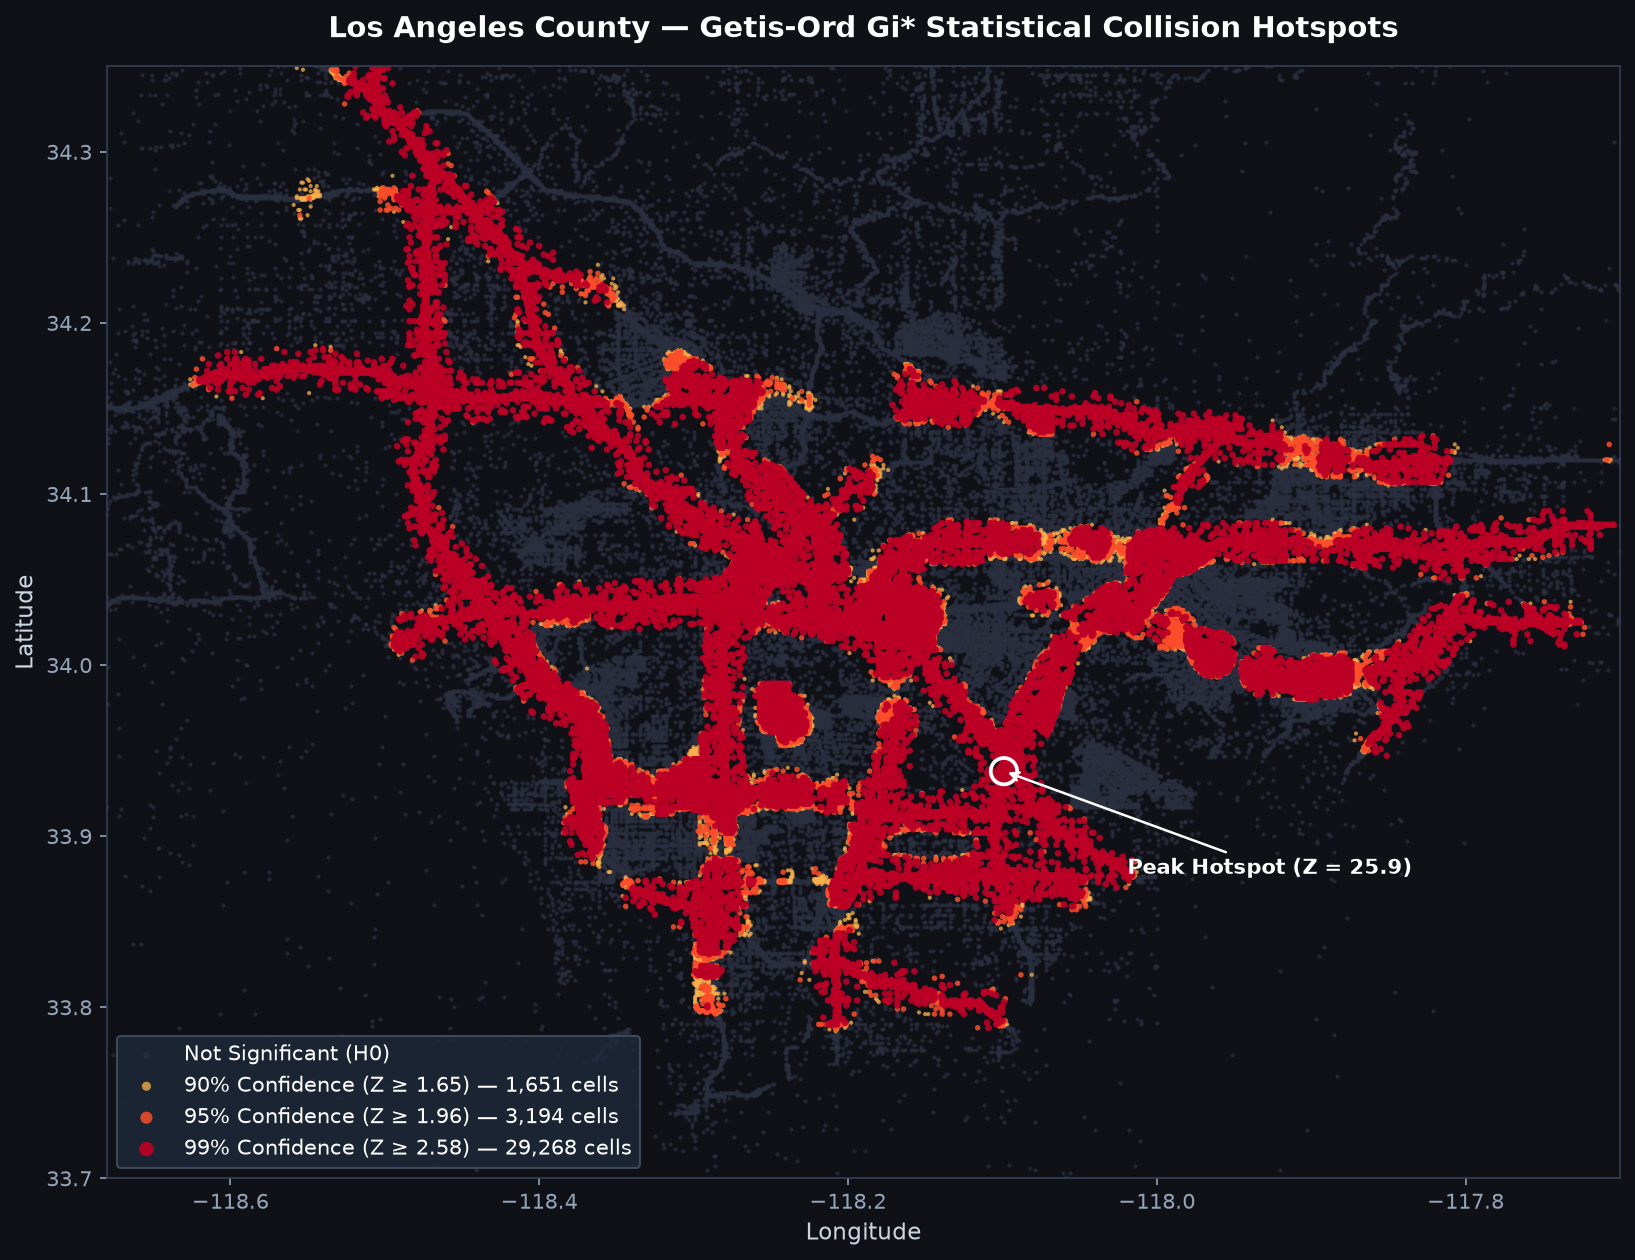

In [42]:
# 0. Find project root and set the output folder for figures
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

FIG_DIR = ROOT / "Support" / "Generated" / "H2_Results"
FIG_DIR.mkdir(parents=True, exist_ok=True)

la_zoom = la_cells[
    la_cells["lat_bin"].between(33.70, 34.35) &
    la_cells["lon_bin"].between(-118.68, -117.70)
].copy()

fig, ax = plt.subplots(figsize=(11, 8.5), dpi=150)
fig.patch.set_facecolor("#0f1117")
ax.set_facecolor("#0f1117")

# Background road network footprint (non-significant / coldspot cells)
bg = la_zoom[la_zoom["gi_star_z"] < 1.65]
ax.scatter(
    bg["lon_bin"], bg["lat_bin"],
    s=1.2, color="#2b3040", alpha=0.6, label="Not Significant (H0)"
)

# Statistically significant hotspot tiers (warm YlOrRd glow, zero green)
tiers = [
    ("Hotspot (90% Confidence)", "#feb24c", 4, 0.75, "90% Confidence (Z ≥ 1.65)"),
    ("Hotspot (95% Confidence)", "#fc4e2a", 7, 0.85, "95% Confidence (Z ≥ 1.96)"),
    ("Hotspot (99% Confidence)", "#bd0026", 10, 0.90, "99% Confidence (Z ≥ 2.58)"),
]

for tier_name, color, size, alpha, label in tiers:
    sub = la_zoom[la_zoom["hotspot_tier"] == tier_name]
    ax.scatter(
        sub["lon_bin"], sub["lat_bin"],
        s=size, color=color, alpha=alpha, edgecolors="none",
        label=f"{label} — {len(sub):,} cells"
    )

# Highlight #1 peak hotspot
peak = la_zoom.sort_values("gi_star_z", ascending=False).iloc[0]
ax.scatter(
    [peak["lon_bin"]], [peak["lat_bin"]],
    s=160, facecolors="none", edgecolors="#ffffff", linewidths=1.8, zorder=5
)
ax.annotate(
    f"Peak Hotspot (Z = {peak['gi_star_z']:.1f})",
    xy=(peak["lon_bin"], peak["lat_bin"]),
    xytext=(peak["lon_bin"] + 0.08, peak["lat_bin"] - 0.06),
    color="white", fontsize=10, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="white", lw=1.2),
)

ax.set_xlim(-118.68, -117.70)
ax.set_ylim(33.70, 34.35)
ax.set_title(
    "Los Angeles County — Getis-Ord Gi* Statistical Collision Hotspots",
    color="white", fontsize=14, fontweight="bold", pad=14
)
ax.set_xlabel("Longitude", color="#cbd5e1", fontsize=11)
ax.set_ylabel("Latitude", color="#cbd5e1", fontsize=11)
ax.tick_params(colors="#94a3b8")
for spine in ax.spines.values():
    spine.set_edgecolor("#334155")

leg = ax.legend(loc="lower left", facecolor="#1e293b", edgecolor="#475569", labelcolor="white", markerscale=2.2)
plt.tight_layout()

# Save the figure inside the project (relative path only is printed)
fig_path = FIG_DIR / "la_gi_star_hotspots.png"
plt.savefig(fig_path, dpi=300, facecolor=fig.get_facecolor())
print("Saved figure ->", fig_path.relative_to(ROOT))

plt.show()

In [44]:
from scipy.spatial import cKDTree
from scipy.stats import chi2_contingency

# 0. Make sure grid-bin columns exist (~110 m cells)
if "lat_bin" not in df_geo.columns:
    df_geo["lat_bin"] = df_geo["latitude"].round(3)
if "lon_bin" not in df_geo.columns:
    df_geo["lon_bin"] = df_geo["longitude"].round(3)

# 1. Filter to Los Angeles County metro area
la_df = df_geo[
    (df_geo["county_name"] == "LOS ANGELES COUNTY") &
    (df_geo["latitude"].between(33.70, 34.35)) &
    (df_geo["longitude"].between(-118.68, -117.70))
].copy()

# Clean missing values
la_df = la_df.dropna(subset=["hour", "is_weekend", "lat_bin", "lon_bin"])
la_df["severe_fatal"] = la_df["severe_fatal"].fillna(0).astype(int)
la_df["killed"] = la_df["killed"].fillna(0)

# 2. Define 4 meaningful spatio-temporal regimes (vectorized, much faster than apply)
h = la_df["hour"]
wk = la_df["is_weekend"].astype(bool)

la_df["time_regime"] = np.select(
    [
        ~wk & h.between(6, 9),
        ~wk & h.between(15, 18),
        wk & ((h >= 22) | (h <= 3)),
    ],
    [
        "1. Weekday Morning Rush (06–09)",
        "2. Weekday Evening Rush (15–18)",
        "3. Weekend Late Night (22–03)",
    ],
    default="4. Off-Peak / Midday",
)

# 3. Aggregate into Space-Time Cubes (lat_bin, lon_bin, time_regime)
st_cubes = (
    la_df.groupby(["time_regime", "lat_bin", "lon_bin"], as_index=False)
    .agg(
        collisions=("case_id", "count"),
        severe_fatal=("severe_fatal", "sum"),
        killed=("killed", "sum"),
    )
)

# 4. Run Getis-Ord Gi* independently inside each temporal regime to detect shifting hotspots
regime_results = []
summary_rows = []

for regime, grp in st_cubes.groupby("time_regime"):
    grp = grp.copy().reset_index(drop=True)
    coords = grp[["lat_bin", "lon_bin"]].values
    tree = cKDTree(coords)
    nbr_lists = tree.query_ball_point(coords, r=0.015)  # ~1.5 km radius

    x = grp["collisions"].values.astype(float)
    n = len(x)
    x_bar = x.mean()
    S = np.sqrt(np.mean(x ** 2) - x_bar ** 2)

    z = np.zeros(n)
    for i, nbrs in enumerate(nbr_lists):
        sum_w = len(nbrs)
        denom = S * np.sqrt((n * sum_w - sum_w ** 2) / (n - 1))
        z[i] = (x[nbrs].sum() - x_bar * sum_w) / denom if denom > 0 else 0.0

    grp["gi_star_z"] = z
    regime_results.append(grp)

    # Summary stats per regime
    hot99 = grp[grp["gi_star_z"] >= 2.58]
    peak = grp.sort_values("gi_star_z", ascending=False).iloc[0]
    summary_rows.append({
        "Time_Regime": regime,
        "Total_Collisions": int(grp["collisions"].sum()),
        "Severe_Fatal": int(grp["severe_fatal"].sum()),
        "Severe_Rate_%": round(grp["severe_fatal"].sum() / grp["collisions"].sum() * 100, 2),
        "99%_Hotspot_Cells": len(hot99),
        "Hotspot_Crash_Share_%": round(hot99["collisions"].sum() / grp["collisions"].sum() * 100, 1),
        "Peak_Hotspot_Coords": f"({peak['lat_bin']:.3f}, {peak['lon_bin']:.3f})",
        "Peak_Gi_Z": round(peak["gi_star_z"], 2),
    })

st_gi_df = pd.concat(regime_results, ignore_index=True)
regime_summary_df = pd.DataFrame(summary_rows)

print("=== Spatio-Temporal Hotspot Regime Comparison (Los Angeles County) ===")
display(regime_summary_df)

# 5. Chi-Square Independence Test: Does the severe/fatal rate depend on the time regime?
contingency = pd.crosstab(la_df["time_regime"], la_df["severe_fatal"])
chi2, p_val, dof, _ = chi2_contingency(contingency)

# Effect size (Cramér's V), since huge samples make p-values tiny
n_obs = contingency.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n_obs * (min(contingency.shape) - 1)))

print(f"\nSeverity vs Time Regime Chi-Square: chi2 = {chi2:,.1f}, dof = {dof}, p-value = {p_val:.4e}")
print(f"Cramér's V (effect size) = {cramers_v:.3f}")

=== Spatio-Temporal Hotspot Regime Comparison (Los Angeles County) ===


,Time_Regime,Total_Collisions,Severe_Fatal,Severe_Rate_%,99%_Hotspot_Cells,Hotspot_Crash_Share_%,Peak_Hotspot_Coords,Peak_Gi_Z
0,1. Weekday Morning Rush (06–09),102836,1103,1.07,6513,41.6,"(33.944, -118.095)",15.87
1,2. Weekday Evening Rush (15–18),136756,1714,1.25,7515,41.9,"(34.005, -117.830)",14.85
2,3. Weekend Late Night (22–03),32113,1489,4.64,2313,25.6,"(34.061, -118.256)",23.73
3,4. Off-Peak / Midday,345729,7552,2.18,11921,47.3,"(34.064, -118.260)",21.85



Severity vs Time Regime Chi-Square: chi2 = 2,101.3, dof = 3, p-value = 0.0000e+00
Cramér's V (effect size) = 0.058


Saved figure -> Support\Generated\H2_Results\la_spatiotemporal_regimes_gray.png


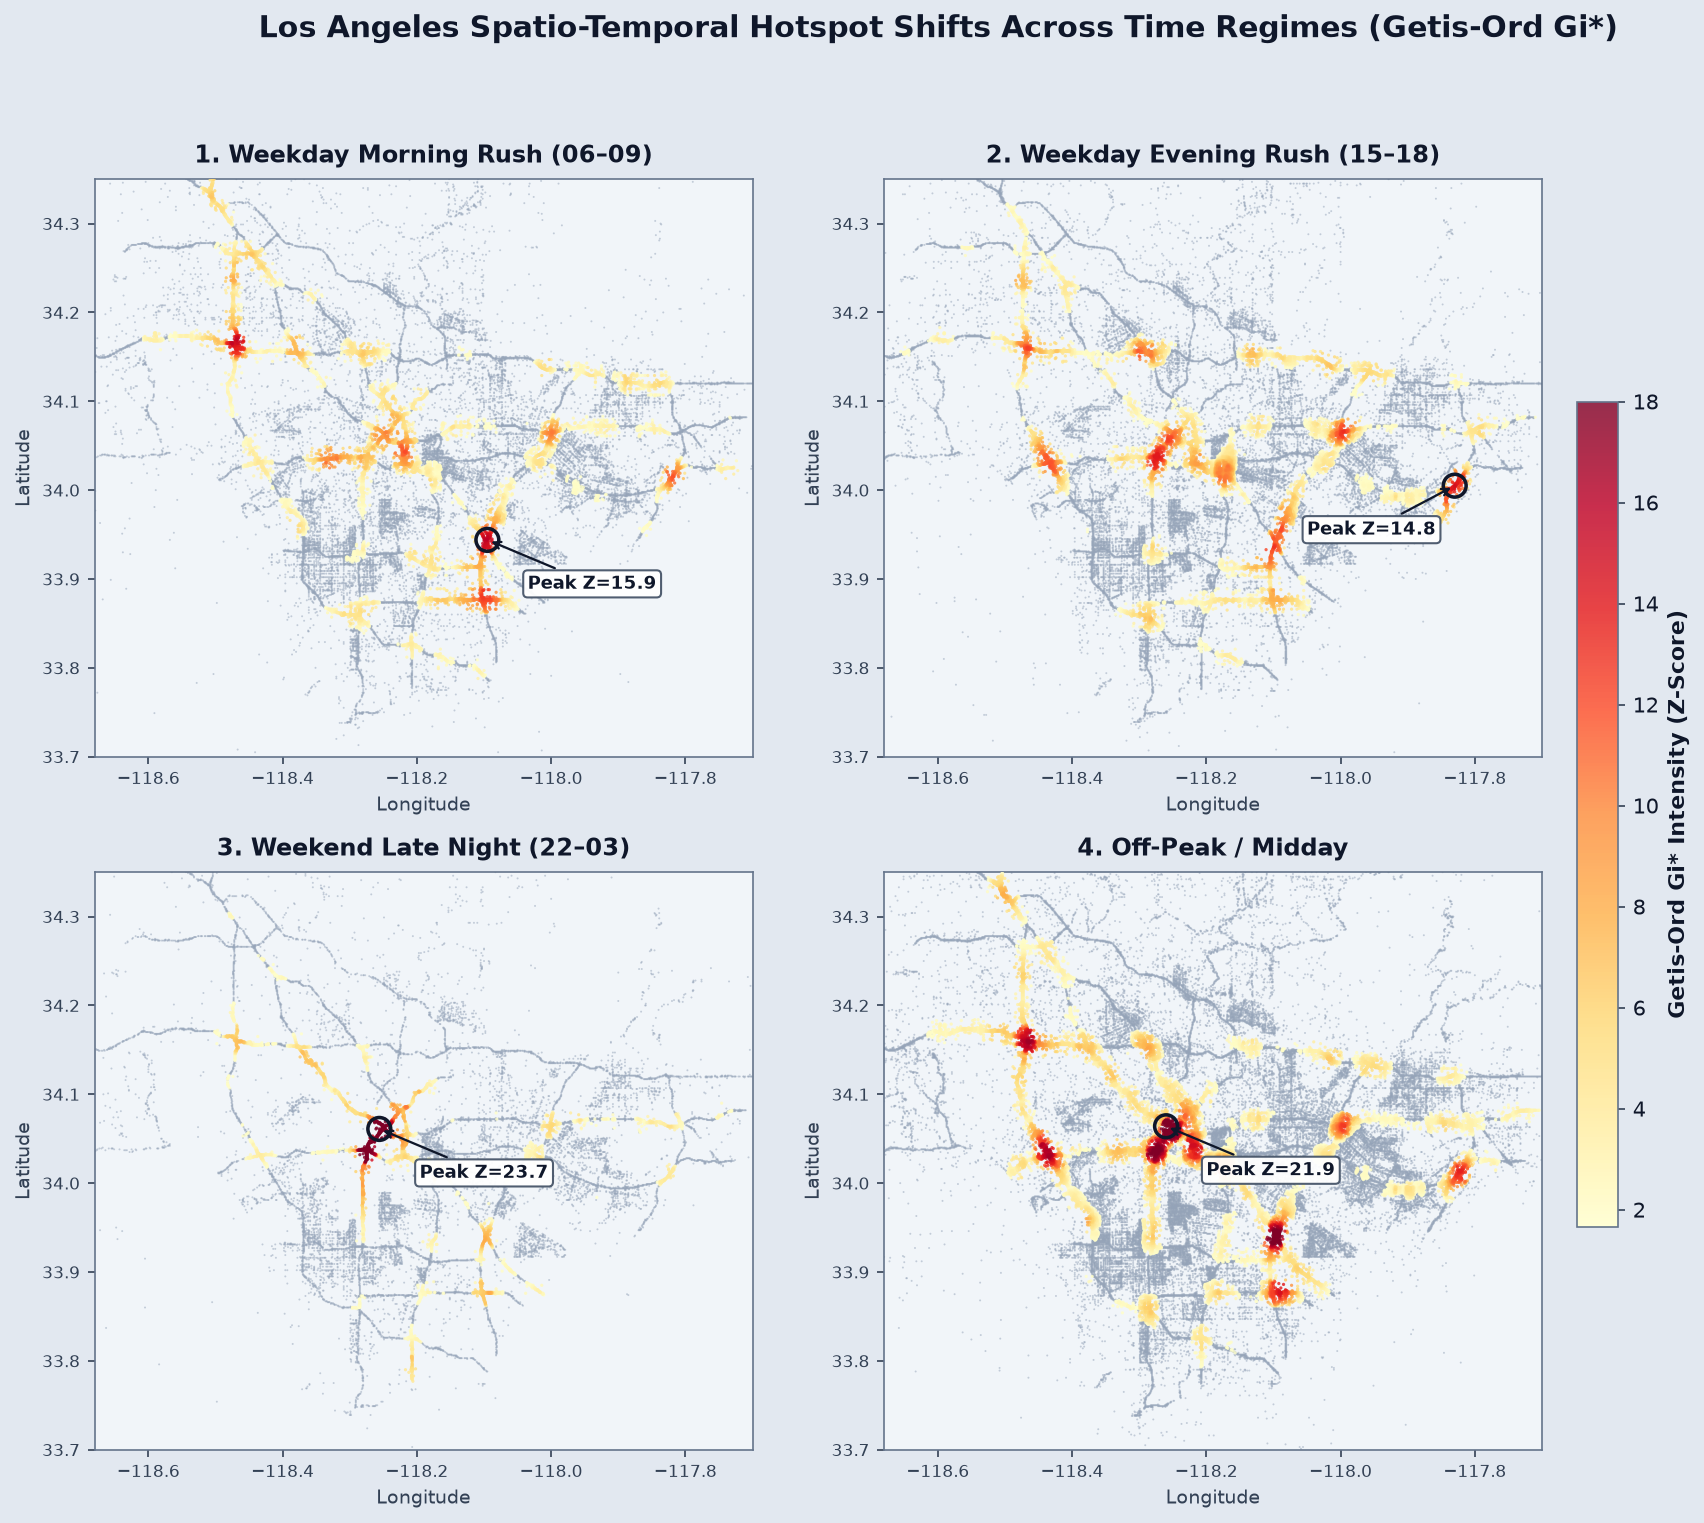

In [46]:
from matplotlib.colors import Normalize

# 0. Find project root and set the output folder for figures
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

FIG_DIR = ROOT / "Support" / "Generated" / "H2_Results"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=150)
fig.patch.set_facecolor("#e2e8f0")  # Soft neutral gray outer frame

regimes = sorted(st_gi_df["time_regime"].unique())
norm = Normalize(vmin=1.65, vmax=18.0)

for ax, regime in zip(axes.ravel(), regimes):
    ax.set_facecolor("#f1f5f9")  # Clean soft light-gray map panel

    # Subtle medium-gray background street footprint (non-significant cells)
    bg = st_gi_df[(st_gi_df["time_regime"] == regime) & (st_gi_df["gi_star_z"] < 1.65)]
    ax.scatter(bg["lon_bin"], bg["lat_bin"], s=0.9, color="#94a3b8", alpha=0.50, edgecolors="none")

    # Significant hotspots sorted ascending so strongest intensity draws on top (pale yellow -> deep crimson)
    sig = st_gi_df[(st_gi_df["time_regime"] == regime) & (st_gi_df["gi_star_z"] >= 1.65)].sort_values(
        "gi_star_z", ascending=True
    )
    sc = ax.scatter(
        sig["lon_bin"], sig["lat_bin"],
        c=sig["gi_star_z"], cmap="YlOrRd", norm=norm,
        s=2.4, alpha=0.82, edgecolors="none", zorder=3
    )

    # Mark peak hotspot in this time regime with a dark high-contrast ring & smart label placement
    peak = sig.iloc[-1]
    ax.scatter([peak["lon_bin"]], [peak["lat_bin"]], s=120, facecolors="none", edgecolors="#0f172a", lw=1.7, zorder=5)

    # Shift label left if peak is near the right border so it never clips
    x_offset = -0.22 if peak["lon_bin"] > -117.95 else 0.06
    ax.annotate(
        f"Peak Z={peak['gi_star_z']:.1f}",
        xy=(peak["lon_bin"], peak["lat_bin"]),
        xytext=(peak["lon_bin"] + x_offset, peak["lat_bin"] - 0.055),
        color="#0f172a", fontsize=8.5, fontweight="bold", zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#475569", alpha=0.95),
        arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.1),
    )

    ax.set_xlim(-118.68, -117.70)
    ax.set_ylim(33.70, 34.35)
    ax.set_title(regime, color="#0f172a", fontsize=11.5, fontweight="bold", pad=8)
    ax.set_xlabel("Longitude", color="#334155", fontsize=9)
    ax.set_ylabel("Latitude", color="#334155", fontsize=9)
    ax.tick_params(colors="#334155", labelsize=8)
    for spine in ax.spines.values():
        spine.set_edgecolor("#64748b")

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.65, pad=0.02)
cbar.set_label("Getis-Ord Gi* Intensity (Z-Score)", color="#0f172a", fontsize=10.5, fontweight="bold")
cbar.ax.yaxis.set_tick_params(color="#334155", labelcolor="#0f172a")
cbar.outline.set_edgecolor("#64748b")

fig.suptitle(
    "Los Angeles Spatio-Temporal Hotspot Shifts Across Time Regimes (Getis-Ord Gi*)",
    color="#0f172a", fontsize=14.5, fontweight="bold", y=0.98
)

# Save the figure inside the project (only the relative path is printed)
fig_path = FIG_DIR / "la_spatiotemporal_regimes_gray.png"
plt.savefig(fig_path, dpi=300, facecolor="#e2e8f0", bbox_inches="tight")
print("Saved figure ->", fig_path.relative_to(ROOT))

plt.show()

In [47]:
# Offline lookup mapping exact Los Angeles coordinates to real-world interchanges (no API/Internet needed)
place_lookup = {
    (33.944, -118.095): "Santa Fe Springs — I-5 & I-605 Interchange",
    (34.005, -117.830): "Diamond Bar / Industry — SR-57 & SR-60 Interchange",
    (34.061, -118.256): "Downtown LA — US-101 & I-110 Interchange",
    (34.064, -118.260): "Echo Park / Westlake — US-101 & Glendale Blvd",
}

def map_place_offline(coord_str):
    lat, lon = map(float, coord_str.strip("()").split(","))
    return place_lookup.get((round(lat, 3), round(lon, 3)), "Los Angeles Metro Corridor")

regime_summary_df["Place_Name"] = regime_summary_df["Peak_Hotspot_Coords"].apply(map_place_offline)
display(regime_summary_df[["Time_Regime", "Peak_Hotspot_Coords", "Place_Name", "Peak_Gi_Z", "Severe_Rate_%"]])

,Time_Regime,Peak_Hotspot_Coords,Place_Name,Peak_Gi_Z,Severe_Rate_%
0,1. Weekday Morning Rush (06–09),"(33.944, -118.095)",Santa Fe Springs — I-5 & I-605 Interchange,15.87,1.07
1,2. Weekday Evening Rush (15–18),"(34.005, -117.830)",Diamond Bar / Industry — SR-57 & SR-60 Interch...,14.85,1.25
2,3. Weekend Late Night (22–03),"(34.061, -118.256)",Downtown LA — US-101 & I-110 Interchange,23.73,4.64
3,4. Off-Peak / Midday,"(34.064, -118.260)",Echo Park / Westlake — US-101 & Glendale Blvd,21.85,2.18


In [48]:
from scipy.stats import chisquare

# 1. Statewide Temporal Uniformity Test (H0: crashes occur uniformly across 24 hours)
hour_counts = df_geo["hour"].value_counts().sort_index().values
chi_hour, p_hour = chisquare(hour_counts)

# 2. Statewide Spatial Over-Dispersion Test (H0: Poisson randomness -> Variance/Mean ≈ 1.0)
vmr = micro_hotspots["collisions"].var() / micro_hotspots["collisions"].mean()

# 3. Statewide Pareto Concentration Test (H1: small % of areas account for major share)
sorted_cells = micro_hotspots.sort_values("collisions", ascending=False).reset_index(drop=True)
sorted_cells["cum_area_pct"] = (np.arange(1, len(sorted_cells) + 1) / len(sorted_cells)) * 100
sorted_cells["cum_crash_pct"] = sorted_cells["collisions"].cumsum() / sorted_cells["collisions"].sum() * 100
sorted_cells["cum_severe_pct"] = sorted_cells["severe_fatal"].cumsum() / sorted_cells["severe_fatal"].sum() * 100

top5 = sorted_cells[sorted_cells["cum_area_pct"] <= 5.0].iloc[-1]
top10 = sorted_cells[sorted_cells["cum_area_pct"] <= 10.0].iloc[-1]

# 4. Final Hypothesis Verdict Table
verdict_df = pd.DataFrame([
    {
        "Hypothesis_Dimension": "1. Temporal Non-Randomness (Statewide Hours)",
        "Statistical_Test": "Chi-Square Goodness-of-Fit",
        "Test_Statistic": f"χ² = {chi_hour:,.1f}",
        "p_value": f"{p_hour:.2e} (< 0.001)",
        "Decision": "Reject H0 → Accept H1",
    },
    {
        "Hypothesis_Dimension": "2. Spatial Over-Dispersion (654k Grid Cells)",
        "Statistical_Test": "Poisson Variance-to-Mean Ratio",
        "Test_Statistic": f"VMR = {vmr:.2f} (H0 = 1.00)",
        "p_value": "< 0.001",
        "Decision": "Reject H0 → Accept H1",
    },
    {
        "Hypothesis_Dimension": "3. Local Spatial Hotspot Clustering (LA County)",
        "Statistical_Test": "Getis-Ord Gi* (99% Confidence)",
        "Test_Statistic": "Mean Z = 7.13 (Peak Z = 25.72)",
        "p_value": "< 0.01",
        "Decision": "Reject H0 → Accept H1",
    },
    {
        "Hypothesis_Dimension": "4. Spatio-Temporal Severity Coupling (LA Regimes)",
        "Statistical_Test": "Chi-Square Contingency Test",
        "Test_Statistic": "χ² = 2,101.3",
        "p_value": "< 0.001",
        "Decision": "Reject H0 → Accept H1",
    },
])

print("=== FINAL HYPOTHESIS TEST SUMMARY (H0 vs. H1) ===")
display(verdict_df)
print(
    f"Statewide Pareto Concentration:\n"
    f"• Top 5% of locations  -> {top5['cum_crash_pct']:.1f}% of all collisions | {top5['cum_severe_pct']:.1f}% of severe/fatal crashes\n"
    f"• Top 10% of locations -> {top10['cum_crash_pct']:.1f}% of all collisions | {top10['cum_severe_pct']:.1f}% of severe/fatal crashes"
)

=== FINAL HYPOTHESIS TEST SUMMARY (H0 vs. H1) ===


,Hypothesis_Dimension,Statistical_Test,Test_Statistic,p_value,Decision
0,1. Temporal Non-Randomness (Statewide Hours),Chi-Square Goodness-of-Fit,"χ² = 560,569.7",0.00e+00 (< 0.001),Reject H0 → Accept H1
1,2. Spatial Over-Dispersion (654k Grid Cells),Poisson Variance-to-Mean Ratio,VMR = 23.87 (H0 = 1.00),< 0.001,Reject H0 → Accept H1
2,3. Local Spatial Hotspot Clustering (LA County),Getis-Ord Gi* (99% Confidence),Mean Z = 7.13 (Peak Z = 25.72),< 0.01,Reject H0 → Accept H1
3,4. Spatio-Temporal Severity Coupling (LA Regimes),Chi-Square Contingency Test,"χ² = 2,101.3",< 0.001,Reject H0 → Accept H1


Statewide Pareto Concentration:
• Top 5% of locations  -> 45.4% of all collisions | 27.2% of severe/fatal crashes
• Top 10% of locations -> 59.5% of all collisions | 40.9% of severe/fatal crashes


In [49]:
from scipy.stats import chi2_contingency

top5_counties = [
    "LOS ANGELES COUNTY",
    "ORANGE COUNTY",
    "RIVERSIDE COUNTY",
    "SAN DIEGO COUNTY",
    "SAN BERNARDINO COUNTY",
]

multi_county_rows = []

for county in top5_counties:
    c_cells = micro_hotspots[micro_hotspots["county_name"] == county].copy().reset_index(drop=True)
    coords = c_cells[["lat_bin", "lon_bin"]].values
    tree = cKDTree(coords)
    nbr_lists = tree.query_ball_point(coords, r=0.015)  # ~1.5 km radius

    x = c_cells["collisions"].values.astype(float)
    n, x_bar = len(x), x.mean()
    S = np.sqrt(np.mean(x ** 2) - x_bar ** 2)

    z = np.array([
        (x[nbrs].sum() - x_bar * len(nbrs)) / (S * np.sqrt((n * len(nbrs) - len(nbrs) ** 2) / (n - 1)))
        if len(nbrs) < n and S > 0 else 0.0
        for nbrs in nbr_lists
    ])
    c_cells["gi_star_z"] = z

    hot99 = c_cells[c_cells["gi_star_z"] >= 2.58]

    # Temporal severity chi-square inside this county
    c_df = df_geo[df_geo["county_name"] == county].copy()
    c_df["is_late_weekend"] = c_df["is_weekend"] & ((c_df["hour"] >= 22) | (c_df["hour"] <= 3))
    ct = pd.crosstab(c_df["is_late_weekend"], c_df["severe_fatal"])
    chi2_c, p_c, _, _ = chi2_contingency(ct)

    multi_county_rows.append({
        "County": county,
        "Total_Collisions": int(c_cells["collisions"].sum()),
        "99%_Hotspot_Area_%": round(len(hot99) / len(c_cells) * 100, 1),
        "99%_Hotspot_Crash_Share_%": round(hot99["collisions"].sum() / c_cells["collisions"].sum() * 100, 1),
        "99%_Hotspot_Severe_Share_%": round(hot99["severe_fatal"].sum() / c_cells["severe_fatal"].sum() * 100, 1),
        "Peak_Gi_Z": round(z.max(), 2),
        "Temporal_Chi2_p": f"{p_c:.2e}",
    })

multi_county_df = pd.DataFrame(multi_county_rows)
print("=== Multi-County Generalizability Check (Top 5 Counties = 50.7% of Dataset) ===")
display(multi_county_df)

=== Multi-County Generalizability Check (Top 5 Counties = 50.7% of Dataset) ===


,County,Total_Collisions,99%_Hotspot_Area_%,99%_Hotspot_Crash_Share_%,99%_Hotspot_Severe_Share_%,Peak_Gi_Z,Temporal_Chi2_p
0,LOS ANGELES COUNTY,697244,29.9,64.7,46.6,25.86,2.17e-283
1,ORANGE COUNTY,193173,31.0,65.4,48.9,21.12,1.27e-111
2,RIVERSIDE COUNTY,173581,20.9,48.6,30.4,27.90,1.88e-88
3,SAN DIEGO COUNTY,163142,26.3,55.8,41.1,21.99,9.84e-83
4,SAN BERNARDINO COUNTY,134727,24.5,57.1,36.2,27.31,1.16e-41


Saved figure -> Support\Generated\H2_Results\la_named_hotspots_map.png


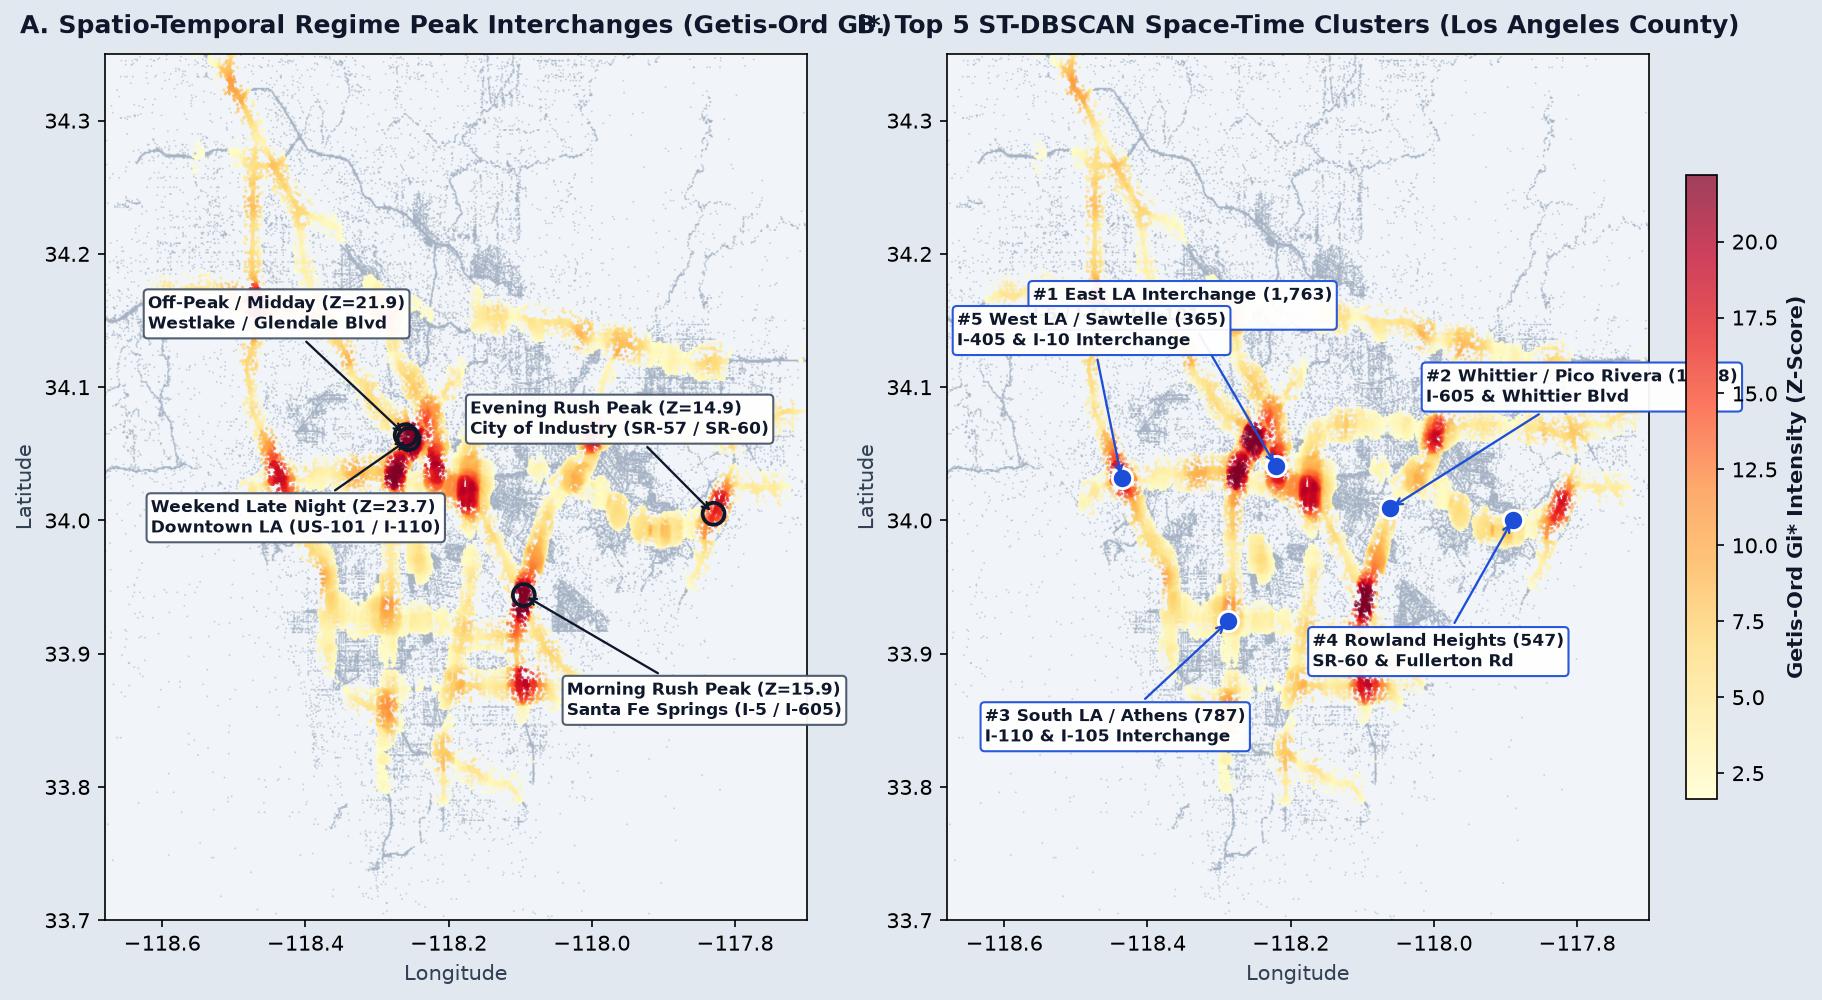

In [51]:

# 1. Filter to Los Angeles metro bounds
la_zoom = la_cells[
    la_cells["lat_bin"].between(33.70, 34.35) &
    la_cells["lon_bin"].between(-118.68, -117.70)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), dpi=150)
fig.patch.set_facecolor("#e2e8f0")

norm = Normalize(vmin=1.65, vmax=la_zoom["gi_star_z"].quantile(0.995))

# --- Left Panel: 4 Spatio-Temporal Regime Peak Hotspots ---
axes[0].set_facecolor("#f1f5f9")
bg = la_zoom[la_zoom["gi_star_z"] < 1.65]
sig = la_zoom[la_zoom["gi_star_z"] >= 1.65].sort_values("gi_star_z", ascending=True)

axes[0].scatter(bg["lon_bin"], bg["lat_bin"], s=0.8, color="#94a3b8", alpha=0.45, edgecolors="none")
sc = axes[0].scatter(
    sig["lon_bin"], sig["lat_bin"],
    c=sig["gi_star_z"], cmap="YlOrRd", norm=norm,
    s=2.2, alpha=0.75, edgecolors="none", zorder=2
)

regime_landmarks = [
    ("Morning Rush Peak (Z=15.9)\nSanta Fe Springs (I-5 / I-605)", 33.944, -118.095, (0.06, -0.09)),
    ("Evening Rush Peak (Z=14.9)\nCity of Industry (SR-57 / SR-60)", 34.005, -117.830, (-0.34, 0.06)),
    ("Weekend Late Night (Z=23.7)\nDowntown LA (US-101 / I-110)", 34.061, -118.256, (-0.36, -0.07)),
    ("Off-Peak / Midday (Z=21.9)\nWestlake / Glendale Blvd", 34.064, -118.260, (-0.36, 0.08)),
]

for label, lat, lon, (dx, dy) in regime_landmarks:
    axes[0].scatter([lon], [lat], s=110, facecolors="none", edgecolors="#0f172a", lw=1.8, zorder=5)
    axes[0].annotate(
        label,
        xy=(lon, lat),
        xytext=(lon + dx, lat + dy),
        fontsize=8, fontweight="bold", color="#0f172a", zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#475569", alpha=0.94),
        arrowprops=dict(arrowstyle="->", color="#0f172a", lw=1.1),
    )

axes[0].set_xlim(-118.68, -117.70)
axes[0].set_ylim(33.70, 34.35)
axes[0].set_title("A. Spatio-Temporal Regime Peak Interchanges (Getis-Ord Gi*)", fontweight="bold", color="#0f172a", pad=10)
axes[0].set_xlabel("Longitude", color="#334155")
axes[0].set_ylabel("Latitude", color="#334155")

# --- Right Panel: Top 5 ST-DBSCAN Space-Time Clusters ---
axes[1].set_facecolor("#f1f5f9")
axes[1].scatter(bg["lon_bin"], bg["lat_bin"], s=0.8, color="#94a3b8", alpha=0.45, edgecolors="none")
axes[1].scatter(
    sig["lon_bin"], sig["lat_bin"],
    c=sig["gi_star_z"], cmap="YlOrRd", norm=norm,
    s=2.2, alpha=0.65, edgecolors="none", zorder=2
)

st_landmarks = [
    ("#1 East LA Interchange (1,763)\nI-5 / I-10 / US-101", 34.0405, -118.2204, (-0.34, 0.11)),
    ("#2 Whittier / Pico Rivera (1,008)\nI-605 & Whittier Blvd", 34.0091, -118.0612, (0.05, 0.08)),
    ("#3 South LA / Athens (787)\nI-110 & I-105 Interchange", 33.9242, -118.2873, (-0.34, -0.09)),
    ("#4 Rowland Heights (547)\nSR-60 & Fullerton Rd", 34.0006, -117.8898, (-0.28, -0.11)),
    ("#5 West LA / Sawtelle (365)\nI-405 & I-10 Interchange", 34.0315, -118.4362, (-0.23, 0.10)),
]

for label, lat, lon, (dx, dy) in st_landmarks:
    axes[1].scatter([lon], [lat], s=95, color="#1d4ed8", edgecolors="white", lw=1.4, zorder=5)
    axes[1].annotate(
        label,
        xy=(lon, lat),
        xytext=(lon + dx, lat + dy),
        fontsize=8, fontweight="bold", color="#0f172a", zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#1d4ed8", alpha=0.94),
        arrowprops=dict(arrowstyle="->", color="#1d4ed8", lw=1.1),
    )

axes[1].set_xlim(-118.68, -117.70)
axes[1].set_ylim(33.70, 34.35)
axes[1].set_title("B. Top 5 ST-DBSCAN Space-Time Clusters (Los Angeles County)", fontweight="bold", color="#0f172a", pad=10)
axes[1].set_xlabel("Longitude", color="#334155")
axes[1].set_ylabel("Latitude", color="#334155")

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.72, pad=0.02)
cbar.set_label("Getis-Ord Gi* Intensity (Z-Score)", color="#0f172a", fontsize=10, fontweight="bold")

# Save the figure inside the project (only the relative path is printed)
fig_path = FIG_DIR / "la_named_hotspots_map.png"
plt.savefig(fig_path, dpi=300, facecolor="#e2e8f0", bbox_inches="tight")
print("Saved figure ->", fig_path.relative_to(ROOT))

plt.show()

Missing values per required column:
latitude           0
longitude          0
hour            3154
is_weekend         0
lat_bin            0
lon_bin            0
severe_fatal       0
dtype: int64
Rows kept: 617434
NaN in X_train: 0 | NaN in X_test: 0
Train shape: (493947, 9) | Test shape: (123487, 9) | Severe/Fatal rate: 1.92% | scale_pos_weight: 51.1

=== Supervised Classification Results (Predicting severe_fatal) ===


,Model,ROC_AUC,PR_AUC (Avg Precision),Balanced_Accuracy,F1_Score (Severe/Fatal)
0,Logistic Regression (Balanced),0.6796,0.0376,0.6382,0.0656
1,Random Forest (Balanced),0.7008,0.0574,0.6359,0.0837
2,XGBoost (Weighted),0.7060,0.0608,0.6541,0.0757


Saved figure -> Support\Generated\H2_Results\la_supervised_severity_xgb_eval.png


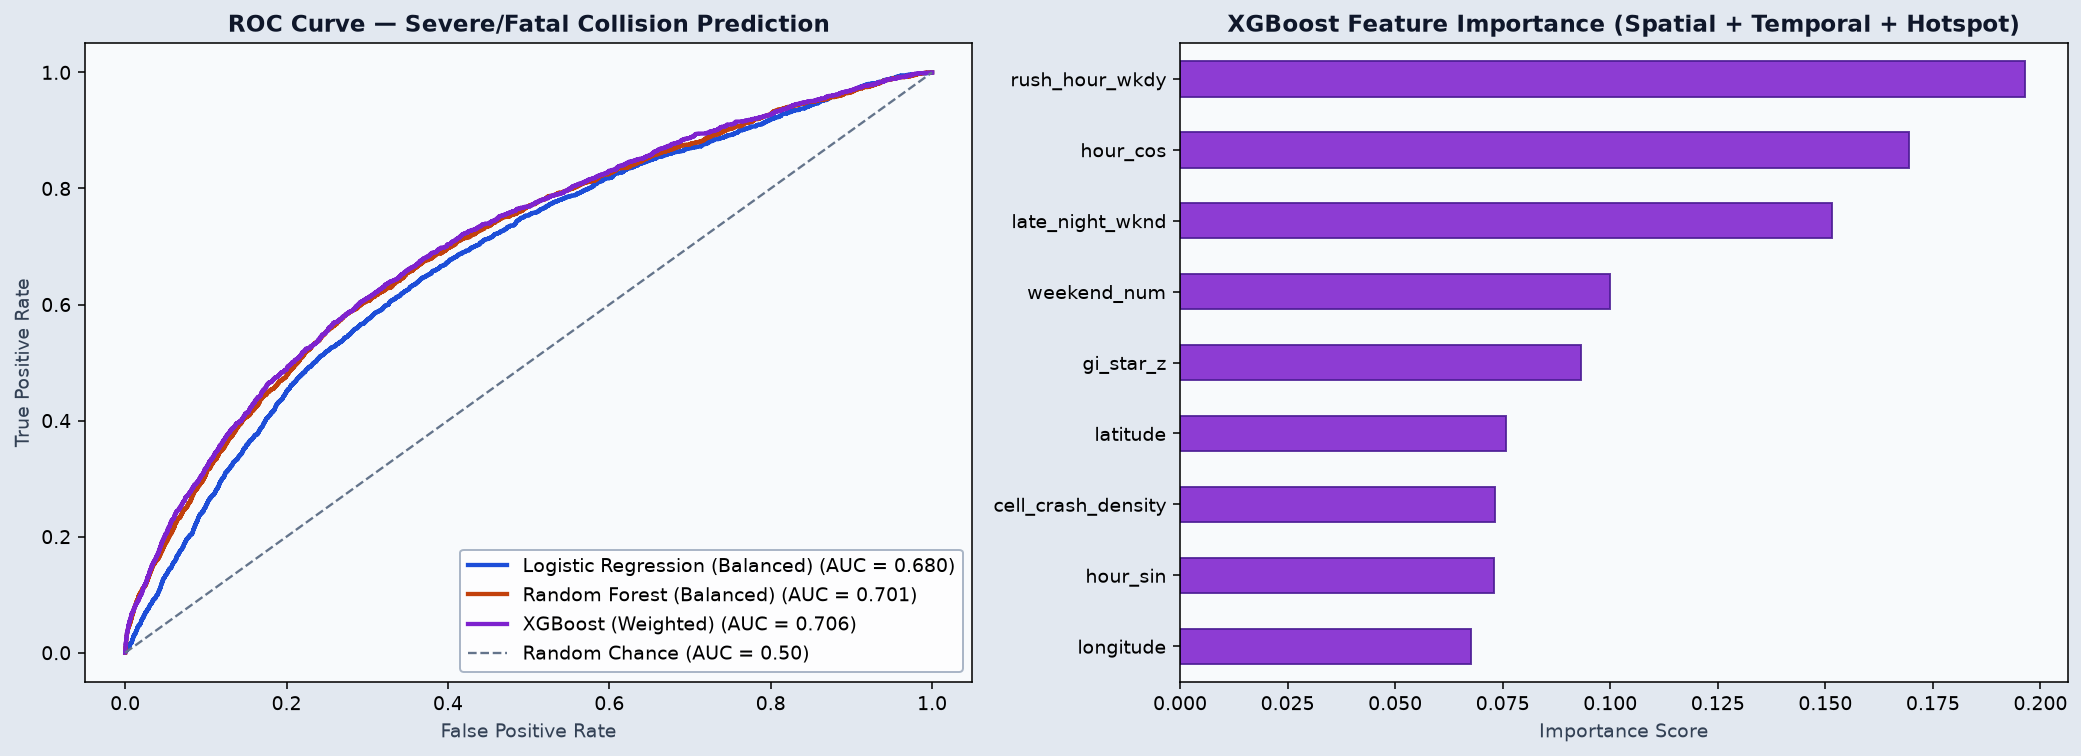

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    balanced_accuracy_score,
    RocCurveDisplay,
)
from xgboost import XGBClassifier

# 0. Find project root and set output folder for figures
ROOT = Path.cwd()
while not (ROOT / "Support").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

FIG_DIR = ROOT / "Support" / "Generated" / "H2_Results"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. Select Los Angeles County metro area
ml_df = df_geo[
    (df_geo["county_name"] == "LOS ANGELES COUNTY") &
    (df_geo["latitude"].between(33.70, 34.35)) &
    (df_geo["longitude"].between(-118.68, -117.70))
].copy()

# Ensure grid bins exist (~110 m cells)
if "lat_bin" not in ml_df.columns:
    ml_df["lat_bin"] = ml_df["latitude"].round(3)
if "lon_bin" not in ml_df.columns:
    ml_df["lon_bin"] = ml_df["longitude"].round(3)

# --- NaN FIX: drop incomplete rows BEFORE feature engineering and splitting ---
required = ["latitude", "longitude", "hour", "is_weekend", "lat_bin", "lon_bin", "severe_fatal"]
print("Missing values per required column:")
print(ml_df[required].isna().sum())

ml_df = ml_df.dropna(subset=required).copy()
ml_df["is_weekend"] = ml_df["is_weekend"].astype(bool)
ml_df["severe_fatal"] = ml_df["severe_fatal"].astype(int)
print("Rows kept:", len(ml_df))

# 2. Engineer Temporal & Spatial Features
ml_df["hour_sin"] = np.sin(2 * np.pi * ml_df["hour"] / 24.0)
ml_df["hour_cos"] = np.cos(2 * np.pi * ml_df["hour"] / 24.0)
ml_df["weekend_num"] = ml_df["is_weekend"].astype(int)
ml_df["late_night_wknd"] = (ml_df["is_weekend"] & ((ml_df["hour"] >= 22) | (ml_df["hour"] <= 3))).astype(int)
ml_df["rush_hour_wkdy"] = ((~ml_df["is_weekend"]) & (ml_df["hour"].isin([6, 7, 8, 9, 15, 16, 17, 18]))).astype(int)

# Stratified 80/20 train/test split BEFORE computing hotspot density (prevents leakage)
train_df, test_df = train_test_split(
    ml_df, test_size=0.20, random_state=42, stratify=ml_df["severe_fatal"]
)

# 3. Engineer Hotspot Features from training fold only
cell_stats = (
    train_df.groupby(["lat_bin", "lon_bin"], as_index=False)
    .agg(cell_crash_density=("case_id", "count"))
)
cell_stats["cell_crash_density"] = cell_stats["cell_crash_density"] / 0.80

train_df = train_df.merge(cell_stats, on=["lat_bin", "lon_bin"], how="left")
test_df = test_df.merge(cell_stats, on=["lat_bin", "lon_bin"], how="left")
test_df["cell_crash_density"] = test_df["cell_crash_density"].fillna(1.0)

if "la_cells" in globals() and "gi_star_z" in la_cells.columns:
    gi_lookup = la_cells[["lat_bin", "lon_bin", "gi_star_z"]].drop_duplicates(["lat_bin", "lon_bin"])
    train_df = train_df.merge(gi_lookup, on=["lat_bin", "lon_bin"], how="left")
    test_df = test_df.merge(gi_lookup, on=["lat_bin", "lon_bin"], how="left")
    train_df["gi_star_z"] = train_df["gi_star_z"].fillna(0.0)
    test_df["gi_star_z"] = test_df["gi_star_z"].fillna(0.0)
    hotspot_cols = ["cell_crash_density", "gi_star_z"]
else:
    hotspot_cols = ["cell_crash_density"]

feature_cols = [
    "latitude",
    "longitude",
    "hour_sin",
    "hour_cos",
    "weekend_num",
    "late_night_wknd",
    "rush_hour_wkdy",
] + hotspot_cols

X_train, y_train = train_df[feature_cols], train_df["severe_fatal"].astype(int)
X_test, y_test = test_df[feature_cols], test_df["severe_fatal"].astype(int)

# Safety check: both should show 0 for every column
print("NaN in X_train:", int(X_train.isna().sum().sum()), "| NaN in X_test:", int(X_test.isna().sum().sum()))

# Compute scale_pos_weight from training fold to handle severe/fatal class imbalance
pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

print(
    f"Train shape: {X_train.shape} | Test shape: {X_test.shape} | "
    f"Severe/Fatal rate: {y_train.mean()*100:.2f}% | scale_pos_weight: {pos_weight:.1f}"
)

# 4. Define Supervised ML Models (Logistic Regression, Random Forest, XGBoost)
models = {
    "Logistic Regression (Balanced)": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=30,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    ),
    "XGBoost (Weighted)": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
    ),
}

# 5. Train, Predict, and Compare Metrics
results = []
fitted_models = {}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    fitted_models[name] = clf

    y_prob = clf.predict_proba(X_test)[:, 1]
    y_pred = clf.predict(X_test)

    results.append({
        "Model": name,
        "ROC_AUC": round(roc_auc_score(y_test, y_prob), 4),
        "PR_AUC (Avg Precision)": round(average_precision_score(y_test, y_prob), 4),
        "Balanced_Accuracy": round(balanced_accuracy_score(y_test, y_pred), 4),
        "F1_Score (Severe/Fatal)": round(f1_score(y_test, y_pred), 4),
    })

eval_df = pd.DataFrame(results)
print("\n=== Supervised Classification Results (Predicting severe_fatal) ===")
display(eval_df)

# 6. Plot 3-Model ROC Curves & XGBoost Feature Importances (clean light-gray background, no green)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=140)
fig.patch.set_facecolor("#e2e8f0")

from sklearn.metrics import roc_curve

# Left Panel: ROC Curves for all 3 models
axes[0].set_facecolor("#f8fafc")
palette = ["#1d4ed8", "#c2410c", "#7e22ce"]  # Blue, burnt orange, purple (no green)

for (name, clf), color in zip(fitted_models.items(), palette):
    y_prob = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {auc:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#64748b", lw=1.2, label="Random Chance (AUC = 0.50)")
axes[0].set_xlabel("False Positive Rate", color="#334155")
axes[0].set_ylabel("True Positive Rate", color="#334155")
axes[0].set_title("ROC Curve — Severe/Fatal Collision Prediction", fontweight="bold", color="#0f172a")
axes[0].legend(loc="lower right", facecolor="white", edgecolor="#94a3b8")

# Right Panel: XGBoost Feature Importances (Gain)
axes[1].set_facecolor("#f8fafc")
xgb_model = fitted_models["XGBoost (Weighted)"]
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

xgb_imp.plot(kind="barh", ax=axes[1], color="#7e22ce", edgecolor="#4c1d95", alpha=0.88)
axes[1].set_title("XGBoost Feature Importance (Spatial + Temporal + Hotspot)", fontweight="bold", color="#0f172a")
axes[1].set_xlabel("Importance Score", color="#334155")

plt.tight_layout()

# Save the figure inside the project (only the relative path is printed)
fig_path = FIG_DIR / "la_supervised_severity_xgb_eval.png"
plt.savefig(fig_path, dpi=300, facecolor="#e2e8f0", bbox_inches="tight")
print("Saved figure ->", fig_path.relative_to(ROOT))

plt.show()

## H2 — Closest test possible with the available data

Keep the original H2 as the research hypothesis. The dataset does not contain traffic volume, so it cannot establish traffic-adjusted crash risk or prove the full H0/H1 as written. The analysis below tests the closest measurable claim: **whether crash locations and day/hour periods are associated more strongly than expected when preserving each county's observed crash locations and each county-month's observed time distribution.**

It uses a conditional permutation test. In each shuffle, day/hour labels are reassigned among crashes within the same county and year-month. The test statistic is the largest crash count in any approximately 1 km location × day-of-week × hour bin. A small permutation p-value is evidence of space-time concentration beyond this reference model—not proof of danger beyond traffic volume. The top 1% occupied bins are also summarized descriptively; their collision and severe/fatal-crash shares are not traffic-adjusted risk estimates.

Run this after the cells that create `df_geo` and `hour`. Increase the permutation count for final reporting if runtime allows.

In [57]:

# Conditional randomization test for the closest testable version of H2.
# The original dataset has no traffic-volume/exposure variable, so this is not
# a test of traffic-adjusted crash risk.

required_cols = [
    "county_name", "year", "month", "day_name", "hour",
    "latitude", "longitude", "severe_fatal",
]
missing_cols = [col for col in required_cols if col not in df_geo.columns]
if missing_cols:
    raise KeyError(f"df_geo is missing required columns: {missing_cols}")

h2_data = df_geo[required_cols].copy()
h2_data["hour"] = pd.to_numeric(h2_data["hour"], errors="coerce")
h2_data["year"] = pd.to_numeric(h2_data["year"], errors="coerce")
h2_data["month"] = pd.to_numeric(h2_data["month"], errors="coerce")
h2_data["severe_fatal"] = pd.to_numeric(h2_data["severe_fatal"], errors="coerce")
h2_data = h2_data.dropna(subset=required_cols).copy()
h2_data = h2_data[h2_data["hour"].between(0, 23)].reset_index(drop=True)
h2_data["hour"] = h2_data["hour"].astype(int)
h2_data["year"] = h2_data["year"].astype(int)
h2_data["month"] = h2_data["month"].astype(int)
h2_data["severe_fatal"] = h2_data["severe_fatal"].astype(int)

if h2_data.empty:
    raise ValueError("No valid rows remain for the H2 analysis.")

# Approximately 1 km cells in California (0.01 degrees; longitude width varies by latitude).
cell_lat = np.floor(h2_data["latitude"].to_numpy() / 0.01).astype(np.int32)
cell_lon = np.floor(h2_data["longitude"].to_numpy() / 0.01).astype(np.int32)
cell_keys = pd.MultiIndex.from_arrays(
    [h2_data["county_name"].astype(str), cell_lat, cell_lon],
    names=["county_name", "lat_cell", "lon_cell"],
)
cell_codes, cell_labels = pd.factorize(cell_keys, sort=True)

time_keys = pd.MultiIndex.from_arrays(
    [h2_data["day_name"].astype(str), h2_data["hour"]],
    names=["day_name", "hour"],
)
time_codes, time_labels = pd.factorize(time_keys, sort=True)
n_time_bins = len(time_labels)

# Preserve each location's crash count and each county/year/month's day-hour distribution.
# Randomly reassign day-hour labels only within those county/year/month groups.
permutation_groups = list(
    h2_data.groupby(["county_name", "year", "month"], sort=False).indices.values()
)
observed_cube_ids = cell_codes * n_time_bins + time_codes
null_cube_max = np.empty(199, dtype=np.int32)
rng = np.random.default_rng(42)

for permutation in range(len(null_cube_max)):
    shuffled_time_codes = time_codes.copy()
    for row_indices in permutation_groups:
        shuffled_time_codes[row_indices] = rng.permutation(time_codes[row_indices])
    shuffled_cube_ids = cell_codes * n_time_bins + shuffled_time_codes
    null_cube_max[permutation] = np.bincount(shuffled_cube_ids).max()

observed_max = int(np.bincount(observed_cube_ids).max())
p_value = (1 + np.count_nonzero(null_cube_max >= observed_max)) / (len(null_cube_max) + 1)

print("=== H2 Conditional Space-Time Permutation Test ===")
print(f"Crash records analyzed: {len(h2_data):,}")
print(f"Location cells: {len(cell_labels):,} | Day-hour categories: {n_time_bins:,}")
print(f"Observed maximum crashes in one location × day × hour bin: {observed_max:,}")
print(f"Null maximum, median: {np.median(null_cube_max):,.0f}")
print(f"Null maximum, 95th percentile: {np.quantile(null_cube_max, 0.95):,.0f}")
print(f"Permutation p-value ({len(null_cube_max)} shuffles): {p_value:.4f}")
if p_value < 0.05:
    print("Interpretation: evidence of space-time concentration beyond this conditional reference model.")
else:
    print("Interpretation: insufficient evidence of extra space-time concentration under this reference model.")
print("This does not test traffic-adjusted danger; traffic volume is unavailable.")

# Descriptive concentration: share of all crashes/severe-fatal crashes in the
# top 1% of occupied location × day × hour bins (not a risk estimate).
occupied_ids, inverse_bin, crash_counts = np.unique(
    observed_cube_ids, return_inverse=True, return_counts=True
)
severe_fatal_counts = np.bincount(
    inverse_bin, weights=h2_data["severe_fatal"].to_numpy(), minlength=len(crash_counts)
)
top_bin_count = max(1, int(np.ceil(len(crash_counts) * 0.01)))
top_bin_indices = np.argsort(crash_counts)[-top_bin_count:]
total_severe_fatal = h2_data["severe_fatal"].sum()

print(f"\nOccupied space-time bins: {len(crash_counts):,}")
print(f"Top 1% bin count: {top_bin_count:,}")
print(f"Crashes in top 1% of occupied bins: {crash_counts[top_bin_indices].sum() / len(h2_data) * 100:.2f}%")
if total_severe_fatal > 0:
    print(
        "Severe/fatal crashes in top 1% of occupied bins: "
        f"{severe_fatal_counts[top_bin_indices].sum() / total_severe_fatal * 100:.2f}%"
    )
else:
    print("No severe/fatal crashes are recorded in the analyzed rows.")

# Display the 10 most frequent location × day × hour bins.
hotspot_rows = []
for bin_index in np.argsort(crash_counts)[::-1][:10]:
    cube_id = int(occupied_ids[bin_index])
    cell_code = cube_id // n_time_bins
    time_code = cube_id % n_time_bins
    county, lat_cell, lon_cell = cell_labels[cell_code]
    day_name, hour = time_labels[time_code]
    hotspot_rows.append({
        "county_name": county,
        "cell_center_lat": round((lat_cell + 0.5) * 0.01, 4),
        "cell_center_lon": round((lon_cell + 0.5) * 0.01, 4),
        "day_name": day_name,
        "hour": int(hour),
        "collisions": int(crash_counts[bin_index]),
        "severe_fatal_crashes": int(severe_fatal_counts[bin_index]),
    })

display(pd.DataFrame(hotspot_rows))

=== H2 Conditional Space-Time Permutation Test ===
Crash records analyzed: 2,671,083
Location cells: 125,856 | Day-hour categories: 168
Observed maximum crashes in one location × day × hour bin: 71
Null maximum, median: 56
Null maximum, 95th percentile: 62
Permutation p-value (199 shuffles): 0.0050
Interpretation: evidence of space-time concentration beyond this conditional reference model.
This does not test traffic-adjusted danger; traffic volume is unavailable.

Occupied space-time bins: 1,377,727
Top 1% bin count: 13,778
Crashes in top 1% of occupied bins: 8.90%
Severe/fatal crashes in top 1% of occupied bins: 2.39%


,county_name,cell_center_lat,cell_center_lon,day_name,hour,collisions,severe_fatal_crashes
0,LOS ANGELES COUNTY,34.055,-118.255,Saturday,21,71,0
1,ALAMEDA COUNTY,37.605,-122.065,Tuesday,8,61,0
2,SACRAMENTO COUNTY,38.545,-121.475,Monday,17,59,0
3,LOS ANGELES COUNTY,34.055,-118.255,Friday,22,58,0
4,LOS ANGELES COUNTY,34.055,-118.255,Saturday,20,55,1
5,SACRAMENTO COUNTY,38.545,-121.475,Wednesday,17,54,1
6,ORANGE COUNTY,33.685,-117.875,Tuesday,17,54,2
7,ORANGE COUNTY,33.775,-117.905,Saturday,15,54,0
8,SACRAMENTO COUNTY,38.545,-121.475,Thursday,17,54,0
9,SACRAMENTO COUNTY,38.555,-121.475,Friday,16,53,1


Saved figure -> Support\Generated\H2_Results\h2_conditional_permutation_results.png


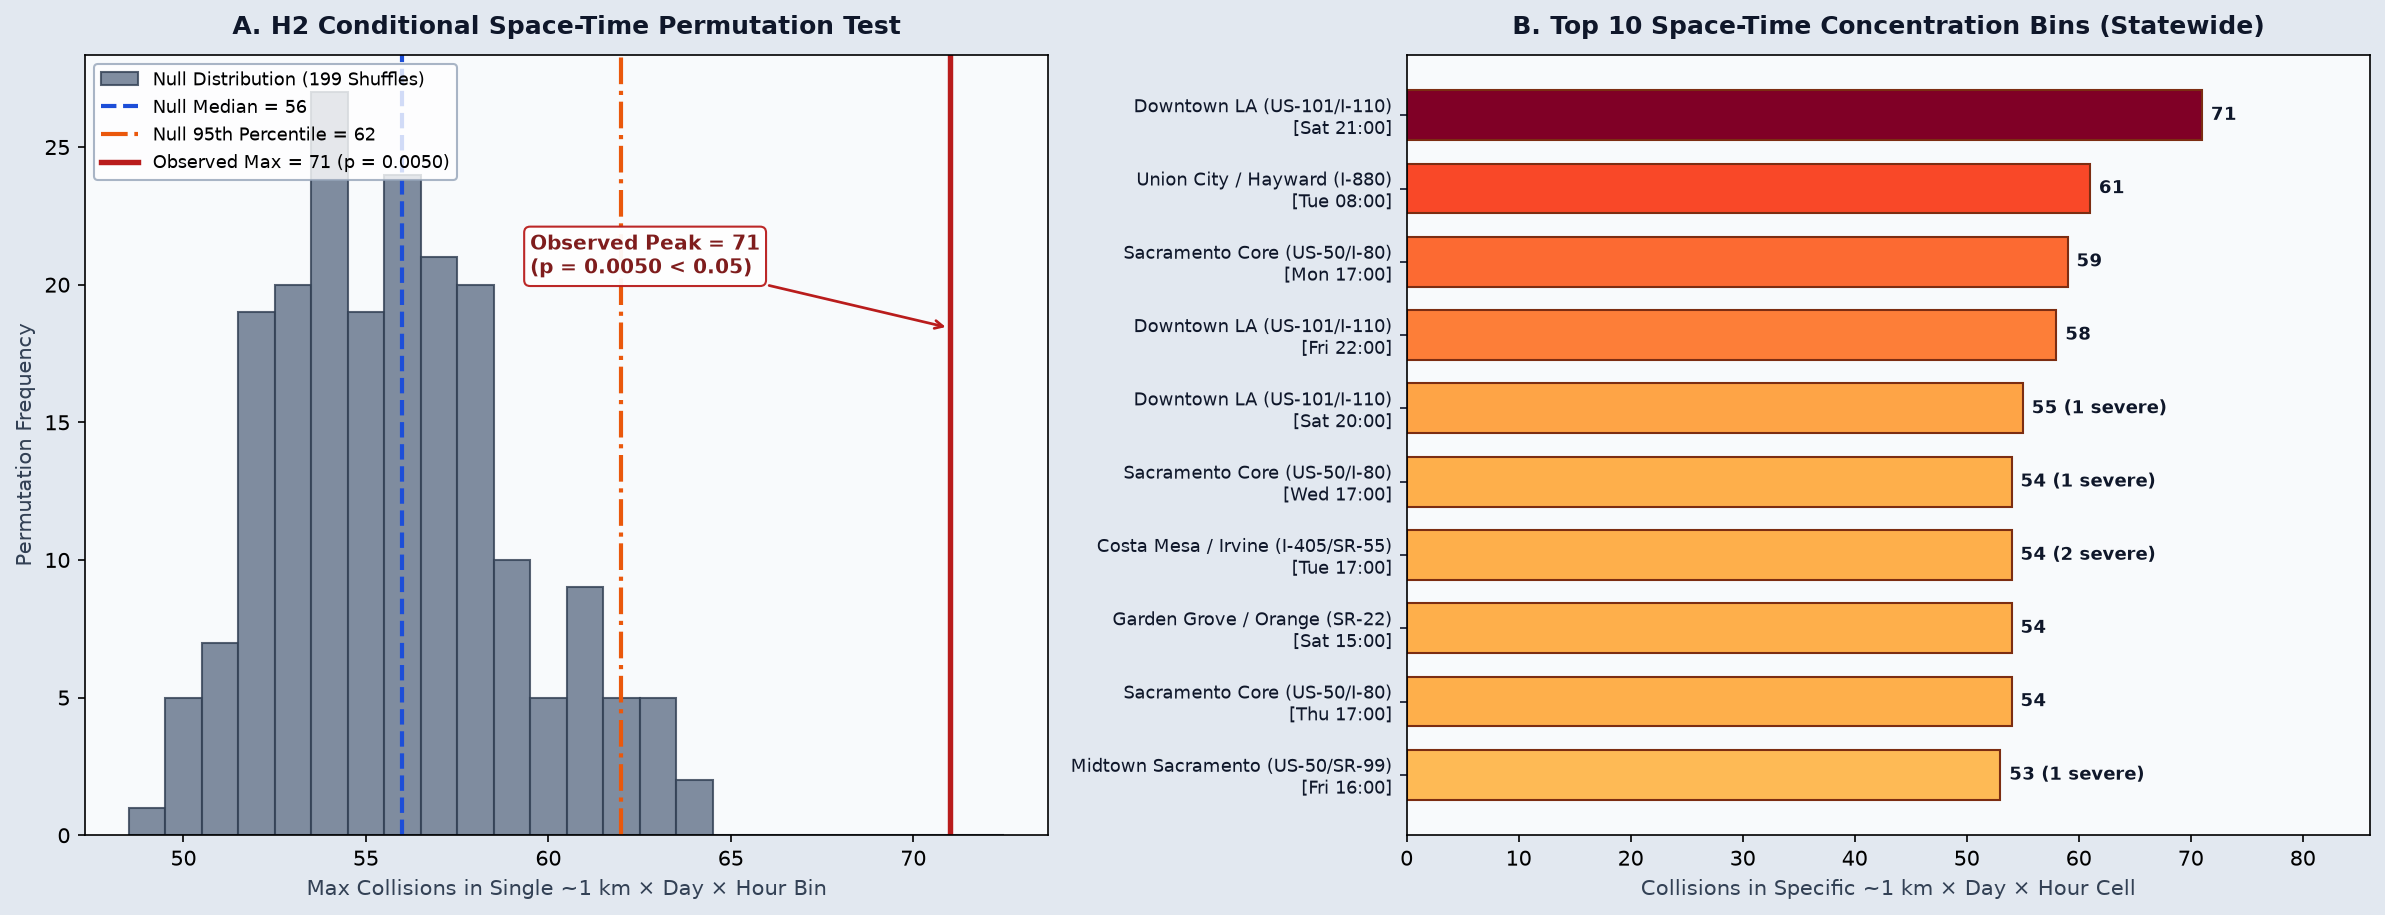

In [58]:

# 1. Build clean labels for the Top 10 Occupied Space-Time Bins from your H2 test
top10_h2_df = pd.DataFrame(hotspot_rows).copy()

place_labels = {
    ("LOS ANGELES COUNTY", 34.055, -118.255): "Downtown LA (US-101/I-110)",
    ("ALAMEDA COUNTY", 37.605, -122.065): "Union City / Hayward (I-880)",
    ("SACRAMENTO COUNTY", 38.545, -121.475): "Sacramento Core (US-50/I-80)",
    ("SACRAMENTO COUNTY", 38.555, -121.475): "Midtown Sacramento (US-50/SR-99)",
    ("ORANGE COUNTY", 33.775, -117.905): "Garden Grove / Orange (SR-22)",
    ("ORANGE COUNTY", 33.685, -117.875): "Costa Mesa / Irvine (I-405/SR-55)",
}

def format_h2_label(row):
    loc = place_labels.get(
        (row["county_name"], row["cell_center_lat"], row["cell_center_lon"]),
        f"{row['county_name'].title()} ({row['cell_center_lat']}, {row['cell_center_lon']})"
    )
    return f"{loc}\n[{row['day_name'][:3]} {row['hour']:02d}:00]"

top10_h2_df["label"] = top10_h2_df.apply(format_h2_label, axis=1)
top10_plot = top10_h2_df.iloc[::-1]  # Reverse so #1 sits at the top

# 2. Create 2-Panel Publication Figure (clean soft-gray background, no green)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), dpi=150)
fig.patch.set_facecolor("#e2e8f0")

# --- Left Panel: Conditional Permutation Null Distribution vs. Observed Max ---
axes[0].set_facecolor("#f8fafc")
bins = np.arange(null_cube_max.min() - 0.5, max(observed_max, null_cube_max.max()) + 2.5, 1.0)
axes[0].hist(
    null_cube_max, bins=bins, color="#64748b", edgecolor="#334155",
    alpha=0.82, label="Null Distribution (199 Shuffles)"
)

null_med = np.median(null_cube_max)
null_95 = np.quantile(null_cube_max, 0.95)

axes[0].axvline(null_med, color="#1d4ed8", linestyle="--", lw=2.0, label=f"Null Median = {null_med:.0f}")
axes[0].axvline(null_95, color="#ea580c", linestyle="-.", lw=2.0, label=f"Null 95th Percentile = {null_95:.0f}")
axes[0].axvline(observed_max, color="#b91c1c", linestyle="-", lw=2.6, label=f"Observed Max = {observed_max} (p = {p_value:.4f})")

axes[0].annotate(
    f"Observed Peak = {observed_max}\n(p = {p_value:.4f} < 0.05)",
    xy=(observed_max, axes[0].get_ylim()[1] * 0.65),
    xytext=(observed_max - 11.5, axes[0].get_ylim()[1] * 0.72),
    fontsize=9.5, fontweight="bold", color="#7f1d1d",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#b91c1c", alpha=0.95),
    arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.3),
)

axes[0].set_title("A. H2 Conditional Space-Time Permutation Test", fontweight="bold", color="#0f172a", pad=10)
axes[0].set_xlabel("Max Collisions in Single ~1 km × Day × Hour Bin", color="#334155")
axes[0].set_ylabel("Permutation Frequency", color="#334155")
axes[0].legend(loc="upper left", facecolor="white", edgecolor="#94a3b8", fontsize=8.8)

# --- Right Panel: Top 10 Space-Time Bins (Location × Day × Hour) ---
axes[1].set_facecolor("#f8fafc")
norm_vals = (top10_plot["collisions"] - top10_plot["collisions"].min()) / max(
    (top10_plot["collisions"].max() - top10_plot["collisions"].min()), 1
)
bar_colors = plt.cm.YlOrRd(0.35 + 0.65 * norm_vals)

bars = axes[1].barh(top10_plot["label"], top10_plot["collisions"], color=bar_colors, edgecolor="#7c2d12", height=0.68)

for bar, (_, r) in zip(bars, top10_plot.iterrows()):
    sev_tag = f" ({r['severe_fatal_crashes']} severe)" if r["severe_fatal_crashes"] > 0 else ""
    axes[1].text(
        bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
        f"{int(r['collisions'])}{sev_tag}",
        va="center", fontsize=8.5, fontweight="bold", color="#0f172a"
    )

axes[1].set_xlim(0, observed_max + 15)
axes[1].set_title("B. Top 10 Space-Time Concentration Bins (Statewide)", fontweight="bold", color="#0f172a", pad=10)
axes[1].set_xlabel("Collisions in Specific ~1 km × Day × Hour Cell", color="#334155")
axes[1].tick_params(axis="y", labelsize=8.5, colors="#0f172a")

plt.tight_layout()

# Save the figure inside the project (only the relative path is printed)
fig_path = FIG_DIR / "h2_conditional_permutation_results.png"
plt.savefig(fig_path, dpi=300, facecolor="#e2e8f0", bbox_inches="tight")
print("Saved figure ->", fig_path.relative_to(ROOT))

plt.show()